# 🏠 House Prices: Advanced Regression with XGBoost

**Competition:** [House Prices - Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques). Predict the sale price of homes in Ames, Iowa.

**Data:** 1,460 training homes and 1,459 test homes, described by **79 features** (areas, quality ratings, neighborhood, year built, garage, basement and more). Many features are missing in a meaningful way (no pool, no alley) and many are ordinal or high-cardinality, so preprocessing matters as much as the model.

**Metric: RMSLE.** Submissions are scored by the root mean squared error between `log(predicted)` and `log(actual)` prices. Errors are judged in percentage terms, so a $20K miss on a $100K house costs more than on a $500K house. We therefore train on `log1p(SalePrice)` and minimize plain RMSE in log space.

**Approach**
1. EDA: target skew, outliers, correlations, missing values
2. Cleaning, feature engineering and encoding (ordinal, target, one-hot)
3. Baseline XGBoost → early stopping → Optuna tuning
4. Stacking (XGBoost + Ridge + Gradient Boosting) with a Ridge meta-learner
5. SHAP explanations, residual analysis and `submission.csv`

**Target:** CV RMSE of about **0.115–0.120 or lower**, which is roughly a top-15% leaderboard score.

In [4]:
# ============================================================
# CELL 1 (companion code): NOTEBOOK ROADMAP
# Prints the plan; no data is touched. Safe to re-run.
# ============================================================
roadmap = [
    ("1",     "Introduction"),
    ("2",     "Imports & setup"),
    ("3",     "Load data & data_description"),
    ("4-9",   "EDA: target, outliers, correlations, categoricals, missing values, near-constant"),
    ("10",    "EDA findings & action plan"),
    ("11",    "Missing value handling"),
    ("12-13", "Feature engineering, drop near-constant features"),
    ("14-16", "Ordinal, target and one-hot encoding"),
    ("17-18", "Skewness correction, target transformation"),
    ("19-21", "Baseline XGBoost, early stopping, Optuna tuning"),
    ("22-23", "Stacking base models and meta-learner"),
    ("24",    "Final model comparison"),
    ("25-26", "SHAP analysis, residual analysis"),
    ("27",    "Generate submission"),
    ("28",    "Conclusions"),
]

print("=" * 70)
print("NOTEBOOK ROADMAP (28 cells)")
print("=" * 70)
for cell, title in roadmap:
    print(f"Cell {cell:<6} {title}")
print("\nMetric: RMSE on log1p(SalePrice), which equals RMSLE on the original prices.")

NOTEBOOK ROADMAP (28 cells)
Cell 1      Introduction
Cell 2      Imports & setup
Cell 3      Load data & data_description
Cell 4-9    EDA: target, outliers, correlations, categoricals, missing values, near-constant
Cell 10     EDA findings & action plan
Cell 11     Missing value handling
Cell 12-13  Feature engineering, drop near-constant features
Cell 14-16  Ordinal, target and one-hot encoding
Cell 17-18  Skewness correction, target transformation
Cell 19-21  Baseline XGBoost, early stopping, Optuna tuning
Cell 22-23  Stacking base models and meta-learner
Cell 24     Final model comparison
Cell 25-26  SHAP analysis, residual analysis
Cell 27     Generate submission
Cell 28     Conclusions

Metric: RMSE on log1p(SalePrice), which equals RMSLE on the original prices.


## Cell 2: Imports & Setup
- Install `optuna`, `shap` and `category_encoders` only if they are missing (needs **Internet: On** in the notebook settings)
- Import all libraries, fix `RANDOM_STATE = 42`, define paths, and print versions

In [5]:
# ============================================================
# CELL 2: IMPORTS & SETUP
# Safe to re-run. Installs only what is missing.
# ============================================================
import os
import sys
import random
import importlib
import subprocess
import warnings

# ---------- Install missing packages (optuna, shap, category_encoders) ----------
REQUIRED = {"optuna": "optuna", "shap": "shap", "category_encoders": "category_encoders"}
failed = []
for module, pip_name in REQUIRED.items():
    try:
        importlib.import_module(module)
    except ImportError:
        print(f"Installing {pip_name} ...")
        result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name],
                                capture_output=True, text=True)
        if result.returncode != 0:
            failed.append(pip_name)
        importlib.invalidate_caches()

if failed:
    print(f"\n[WARNING] Could not install: {failed}")
    print("Turn on Internet in the notebook settings (right sidebar -> Session options), then re-run this cell.")

# ---------- Core imports ----------
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import lightgbm
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

optional = {}
for module in REQUIRED:
    try:
        optional[module] = importlib.import_module(module)
    except ImportError:
        optional[module] = None

# ---------- Reproducibility ----------
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)

# ---------- Paths ----------
WORKING_DIR = "/kaggle/working"
os.makedirs(WORKING_DIR, exist_ok=True)
SUBMISSION_PATH = f"{WORKING_DIR}/submission.csv"

CANDIDATE_DIRS = [
    "/kaggle/input/house-prices-advanced-regression-techniques",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
]
INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
if INPUT_DIR is None and os.path.exists("/kaggle/input"):
    for root, _, files in os.walk("/kaggle/input"):
        if "train.csv" in files and "test.csv" in files:
            INPUT_DIR = root
            break

# ---------- Plot defaults ----------
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
sns.set_style("whitegrid")

# ---------- Version report ----------
print("=" * 55)
print("ENVIRONMENT")
print("=" * 55)
print(f"Python            : {sys.version.split()[0]}")
print(f"NumPy             : {np.__version__}")
print(f"Pandas            : {pd.__version__}")
print(f"Matplotlib        : {matplotlib.__version__}")
print(f"Seaborn           : {sns.__version__}")
print(f"scikit-learn      : {sklearn.__version__}")
print(f"XGBoost           : {xgboost.__version__}")
print(f"LightGBM          : {lightgbm.__version__}")
for module, mod in optional.items():
    version = getattr(mod, "__version__", "installed") if mod else "NOT AVAILABLE"
    print(f"{module:<18}: {version}")
print(f"RANDOM_STATE      : {RANDOM_STATE}")

# ---------- Data check ----------
print("\n" + "=" * 55)
print("DATA")
print("=" * 55)
if INPUT_DIR is None:
    print("[MISSING] Competition data not found. Add it via 'Add Input' in the sidebar.")
else:
    print(f"Data folder: {INPUT_DIR}")
    for name in ["train.csv", "test.csv", "data_description.txt", "sample_submission.csv"]:
        path = f"{INPUT_DIR}/{name}"
        status = f"OK ({os.path.getsize(path)/1024:,.1f} KB)" if os.path.exists(path) else "MISSING"
        print(f"{name:<22}: {status}")

print(f"\nWorking dir writable: {os.access(WORKING_DIR, os.W_OK)}")

ENVIRONMENT
Python            : 3.13.18
NumPy             : 2.1.3
Pandas            : 2.3.3
Matplotlib        : 3.10.0
Seaborn           : 0.13.2
scikit-learn      : 1.6.1
XGBoost           : 3.4.1
LightGBM          : 4.6.0
optuna            : 5.1.0
shap              : 0.54.1
category_encoders : 2.11.2
RANDOM_STATE      : 42

DATA
Data folder: /kaggle/input/competitions/house-prices-advanced-regression-techniques
train.csv             : OK (449.9 KB)
test.csv              : OK (440.8 KB)
data_description.txt  : OK (13.1 KB)
sample_submission.csv : OK (31.2 KB)

Working dir writable: True


## Cell 3: Load Data & data_description
- Load `train.csv` and `test.csv`, check shapes, and keep untouched raw copies
- Parse `data_description.txt` into a summary (79 features and their levels)
- Group features by type (continuous, discrete, ordinal, nominal, numeric-coded categories) and save the grouping to a checkpoint

In [6]:
# ============================================================
# CELL 3: LOAD DATA & DATA_DESCRIPTION
# Read-only. Safe to re-run. Self-contained after a restart.
# ============================================================
import os
import re
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ---------- Restart-safe essentials ----------
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
os.makedirs(WORKING_DIR, exist_ok=True)
CKPT_TYPES = f"{WORKING_DIR}/ckpt_00_feature_types.pkl"

CANDIDATE_DIRS = [
    "/kaggle/input/house-prices-advanced-regression-techniques",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
]
INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
if INPUT_DIR is None:
    raise FileNotFoundError("train.csv not found. Re-run Cell 2 and check the data is attached.")

# ---------- Load ----------
train_raw  = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_raw   = pd.read_csv(f"{INPUT_DIR}/test.csv")
sample_sub = pd.read_csv(f"{INPUT_DIR}/sample_submission.csv")

print("=" * 55)
print("SHAPES")
print("=" * 55)
print(f"train: {train_raw.shape} | test: {test_raw.shape} | sample_submission: {sample_sub.shape}")
feature_cols = [c for c in train_raw.columns if c not in ("Id", "SalePrice")]
print(f"Features (excl. Id, SalePrice): {len(feature_cols)}")
print(f"Test has the same features: {set(feature_cols) == set(test_raw.columns) - {'Id'}}")
print(f"Duplicate rows (train): {train_raw.duplicated().sum()} | "
      f"Test Ids match sample: {set(test_raw['Id']) == set(sample_sub['Id'])}")

# ---------- Parse data_description.txt ----------
desc, current = {}, None
with open(f"{INPUT_DIR}/data_description.txt", encoding="latin-1") as f:
    for line in f:
        line = line.rstrip("\n")
        if not line.strip():
            continue
        m = re.match(r"^(\w+):\s*(.*)$", line)          # unindented line = new feature
        if m:
            current = m.group(1)
            desc[current] = {"description": m.group(2).strip(), "levels": []}
        elif current is not None:
            desc[current]["levels"].append(line.strip())

print("\n" + "=" * 55)
print("DATA DESCRIPTION SUMMARY")
print("=" * 55)
print(f"Features documented: {len(desc)}")
in_desc_not_data = set(desc) - set(feature_cols)
in_data_not_desc = set(feature_cols) - set(desc)
print(f"In description but not in data: {sorted(in_desc_not_data) or 'none'}")
print(f"In data but not in description: {sorted(in_data_not_desc) or 'none'}")
print("\nFirst 12 features:")
for name in list(desc)[:12]:
    d = desc[name]
    print(f"  {name:<14} {len(d['levels']):>2} levels | {d['description'][:55]}")

# ---------- Feature type grouping ----------
ORDINAL_CAT = [   # string-coded quality / condition / exposure scales
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "HeatingQC", "KitchenQual", "FireplaceQu",
    "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence",
    "Functional", "LandSlope", "LotShape", "PavedDrive",
]
NUMERIC_ORDINAL = ["OverallQual", "OverallCond"]              # already integer-coded 1-10
NUMERIC_CODED_CAT = ["MSSubClass", "MoSold", "YrSold"]        # numbers that are really categories
YEAR_COLS = ["YearBuilt", "YearRemodAdd", "GarageYrBlt"]
DISCRETE_COUNT = ["BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath", "BedroomAbvGr",
                  "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageCars"]

object_cols  = train_raw[feature_cols].select_dtypes(exclude=[np.number]).columns.tolist()
numeric_cols = train_raw[feature_cols].select_dtypes(include=[np.number]).columns.tolist()

NOMINAL = [c for c in object_cols if c not in ORDINAL_CAT]
special = set(NUMERIC_ORDINAL + NUMERIC_CODED_CAT + YEAR_COLS + DISCRETE_COUNT)
CONTINUOUS = [c for c in numeric_cols if c not in special]

groups = {
    "Continuous numeric": CONTINUOUS,
    "Discrete counts": DISCRETE_COUNT,
    "Year columns": YEAR_COLS,
    "Numeric ordinal (1-10)": NUMERIC_ORDINAL,
    "Numeric-coded categories": NUMERIC_CODED_CAT,
    "Ordinal (string-coded)": ORDINAL_CAT,
    "Nominal categorical": NOMINAL,
}
assert sum(len(v) for v in groups.values()) == len(feature_cols), "Some features are not grouped"
assert len(set(sum(groups.values(), []))) == len(feature_cols), "A feature is in two groups"

print("\n" + "=" * 55)
print("FEATURE TYPES")
print("=" * 55)
for g, cols in groups.items():
    print(f"{g:<26}: {len(cols):>2}")
print(f"{'Total':<26}: {sum(len(v) for v in groups.values()):>2}")
print(f"\nNominal categorical columns: {NOMINAL}")

# ---------- Checkpoint ----------
pd.to_pickle({"groups": groups, "feature_cols": feature_cols}, CKPT_TYPES)
print(f"\nSaved {os.path.basename(CKPT_TYPES)}")

SHAPES
train: (1460, 81) | test: (1459, 80) | sample_submission: (1459, 2)
Features (excl. Id, SalePrice): 79
Test has the same features: True
Duplicate rows (train): 0 | Test Ids match sample: True

DATA DESCRIPTION SUMMARY
Features documented: 79
In description but not in data: ['Bedroom', 'Kitchen']
In data but not in description: ['BedroomAbvGr', 'KitchenAbvGr']

First 12 features:
  MSSubClass     16 levels | Identifies the type of dwelling involved in the sale.
  MSZoning        8 levels | Identifies the general zoning classification of the sal
  LotFrontage     0 levels | Linear feet of street connected to property
  LotArea         0 levels | Lot size in square feet
  Street          2 levels | Type of road access to property
  Alley           3 levels | Type of alley access to property
  LotShape        4 levels | General shape of property
  LandContour     4 levels | Flatness of the property
  Utilities       4 levels | Type of utilities available
  LotConfig       5 levels |

## Cell 4: EDA, SalePrice
- Compare raw `SalePrice` with `log1p(SalePrice)` (histograms, Q-Q plots, skewness, kurtosis)
- Confirm that a log transformation is needed

TARGET STATISTICS
           SalePrice  log1p(SalePrice)
mean      180921.196            12.024
median    163000.000            12.002
std        79442.503             0.399
skewness       1.883             0.121
kurtosis       6.536             0.810


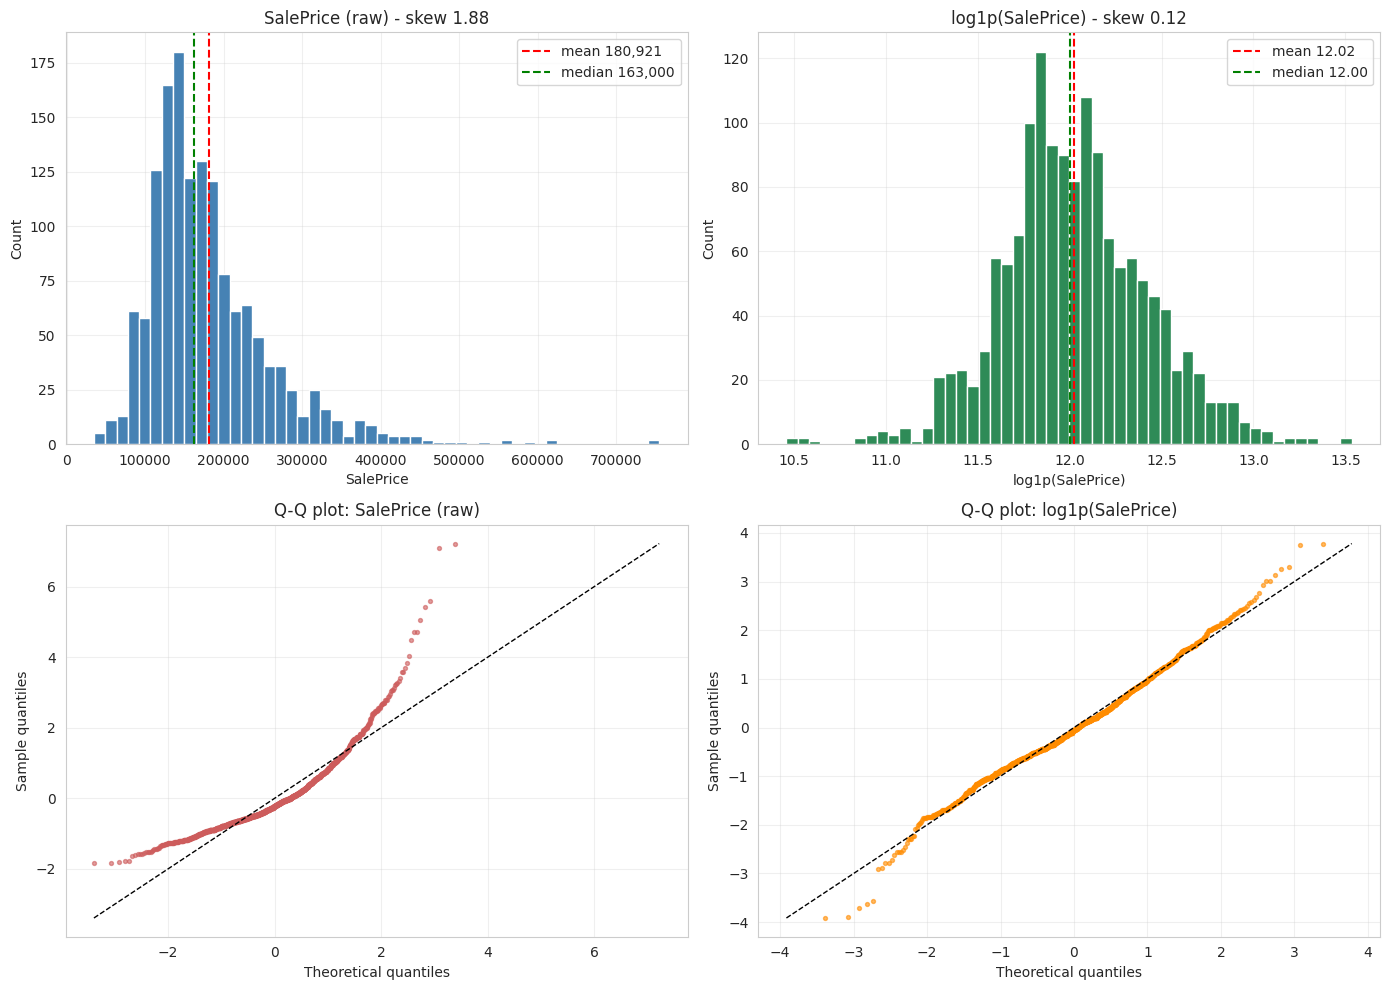

DECISION
Skewness before: 1.883 | after log1p: 0.121
Log transformation needed: True
-> Model log1p(SalePrice); RMSE in log space equals the competition's RMSLE.
-> Final predictions are converted back with expm1.


In [7]:
# ============================================================
# CELL 4: EDA - SALEPRICE
# Read-only. Safe to re-run. Self-contained.
# ============================================================
import os
import random
import warnings
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

CANDIDATE_DIRS = [
    "/kaggle/input/house-prices-advanced-regression-techniques",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
]
INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
if INPUT_DIR is None:
    raise FileNotFoundError("train.csv not found. Re-run Cell 2 and check the data is attached.")
train_raw = pd.read_csv(f"{INPUT_DIR}/train.csv")

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

y_raw = train_raw["SalePrice"]
y_log = np.log1p(y_raw)

# ---------- Statistics ----------
stats = pd.DataFrame({
    "SalePrice": [y_raw.mean(), y_raw.median(), y_raw.std(), y_raw.skew(), y_raw.kurt()],
    "log1p(SalePrice)": [y_log.mean(), y_log.median(), y_log.std(), y_log.skew(), y_log.kurt()],
}, index=["mean", "median", "std", "skewness", "kurtosis"])

print("=" * 55)
print("TARGET STATISTICS")
print("=" * 55)
print(stats.round(3).to_string())

# ---------- Q-Q helper (numpy + stdlib only) ----------
def qq_points(series):
    n = len(series)
    sample = np.sort(((series - series.mean()) / series.std()).values)
    nd = NormalDist()
    theo = np.array([nd.inv_cdf((i - 0.5) / n) for i in range(1, n + 1)])
    return theo, sample

# ---------- Plots ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(y_raw, bins=50, color="steelblue", edgecolor="white")
axes[0, 0].axvline(y_raw.mean(), color="red", linestyle="--", label=f"mean {y_raw.mean():,.0f}")
axes[0, 0].axvline(y_raw.median(), color="green", linestyle="--", label=f"median {y_raw.median():,.0f}")
axes[0, 0].set_title(f"SalePrice (raw) - skew {y_raw.skew():.2f}")
axes[0, 0].set_xlabel("SalePrice"); axes[0, 0].set_ylabel("Count"); axes[0, 0].legend()

axes[0, 1].hist(y_log, bins=50, color="seagreen", edgecolor="white")
axes[0, 1].axvline(y_log.mean(), color="red", linestyle="--", label=f"mean {y_log.mean():.2f}")
axes[0, 1].axvline(y_log.median(), color="green", linestyle="--", label=f"median {y_log.median():.2f}")
axes[0, 1].set_title(f"log1p(SalePrice) - skew {y_log.skew():.2f}")
axes[0, 1].set_xlabel("log1p(SalePrice)"); axes[0, 1].set_ylabel("Count"); axes[0, 1].legend()

for ax, series, title, color in [
    (axes[1, 0], y_raw, "Q-Q plot: SalePrice (raw)", "indianred"),
    (axes[1, 1], y_log, "Q-Q plot: log1p(SalePrice)", "darkorange"),
]:
    theo, sample = qq_points(series)
    ax.scatter(theo, sample, s=8, alpha=0.6, color=color)
    lims = [min(theo.min(), sample.min()), max(theo.max(), sample.max())]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_title(title); ax.set_xlabel("Theoretical quantiles"); ax.set_ylabel("Sample quantiles")

plt.tight_layout()
plt.show()

# ---------- Decision ----------
print("=" * 55)
print("DECISION")
print("=" * 55)
print(f"Skewness before: {y_raw.skew():.3f} | after log1p: {y_log.skew():.3f}")
needs_log = abs(y_raw.skew()) > 0.75 and abs(y_log.skew()) < abs(y_raw.skew())
print(f"Log transformation needed: {needs_log}")
print("-> Model log1p(SalePrice); RMSE in log space equals the competition's RMSLE.")
print("-> Final predictions are converted back with expm1.")

## Cell 5: EDA, Outlier Detection
- Plot `GrLivArea` vs `SalePrice` and flag the 2 huge houses sold cheaply (`GrLivArea > 4000` and `SalePrice < 300000`)
- Remove them, document the removed rows, and save `ckpt_01_train_no_outliers.pkl`

6 LARGEST HOUSES BY GrLivArea
  Id  GrLivArea  TotalBsmtSF  OverallQual SaleCondition  SalePrice
1299       5642         6110           10       Partial     160000
 524       4676         3138           10       Partial     184750
1183       4476         2396           10       Abnorml     745000
 692       4316         2444           10        Normal     755000
1170       3627         1930           10        Normal     625000
 186       3608         1107           10        Normal     475000

OUTLIERS REMOVED (GrLivArea > 4000 & SalePrice < 300000)
  Id  GrLivArea  TotalBsmtSF  OverallQual SaleCondition  SalePrice
 524       4676         3138           10       Partial     184750
1299       5642         6110           10       Partial     160000

Train rows: 1460 -> 1458
Correlation GrLivArea vs log1p(SalePrice): 0.701 -> 0.725


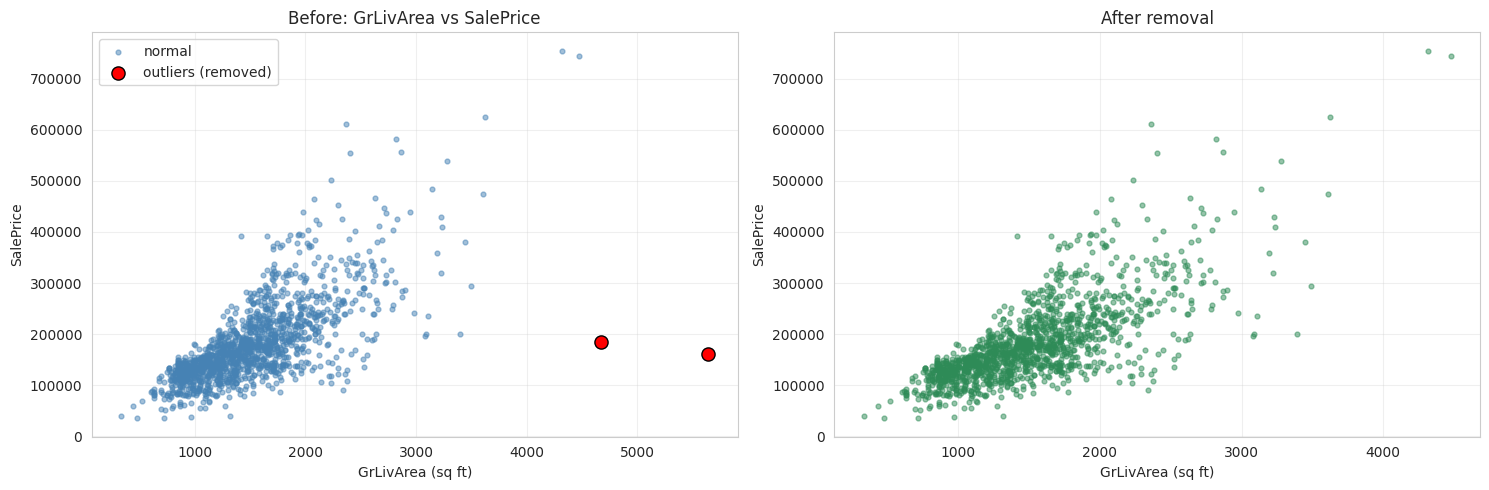

OTHER EXTREME VALUES (inspection only, not removed)
LotArea:
 Id  LotArea  SalePrice
314   215245     375000
336   164660     228950

TotalBsmtSF:
 Id  TotalBsmtSF  SalePrice
333         3206     284000
497         3200     430000

LotFrontage:
  Id  LotFrontage  SalePrice
 935        313.0     242000
1128        182.0     259000

Saved ckpt_01_train_no_outliers.pkl | removed Ids: [524, 1299]


In [8]:
# ============================================================
# CELL 5: EDA - OUTLIER DETECTION & REMOVAL
# Safe to re-run. Raw data is never modified; saves a checkpoint.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
os.makedirs(WORKING_DIR, exist_ok=True)
CKPT_NO_OUTLIERS = f"{WORKING_DIR}/ckpt_01_train_no_outliers.pkl"

CANDIDATE_DIRS = [
    "/kaggle/input/house-prices-advanced-regression-techniques",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
]
INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
if INPUT_DIR is None:
    raise FileNotFoundError("train.csv not found. Re-run Cell 2 and check the data is attached.")
train_raw = pd.read_csv(f"{INPUT_DIR}/train.csv")

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ---------- Look at the largest houses ----------
cols_show = ["Id", "GrLivArea", "TotalBsmtSF", "OverallQual", "SaleCondition", "SalePrice"]
print("=" * 55)
print("6 LARGEST HOUSES BY GrLivArea")
print("=" * 55)
print(train_raw.nlargest(6, "GrLivArea")[cols_show].to_string(index=False))

# ---------- Flag outliers ----------
outlier_mask = (train_raw["GrLivArea"] > 4000) & (train_raw["SalePrice"] < 300000)
removed = train_raw.loc[outlier_mask, cols_show]
removed_ids = removed["Id"].tolist()

print("\n" + "=" * 55)
print("OUTLIERS REMOVED (GrLivArea > 4000 & SalePrice < 300000)")
print("=" * 55)
print(removed.to_string(index=False))
assert len(removed_ids) == 2, f"Expected 2 outliers, found {len(removed_ids)}"

train_no_outliers = train_raw.loc[~outlier_mask].reset_index(drop=True)
print(f"\nTrain rows: {len(train_raw)} -> {len(train_no_outliers)}")

# ---------- Effect on the relationship ----------
r_before = np.corrcoef(train_raw["GrLivArea"], np.log1p(train_raw["SalePrice"]))[0, 1]
r_after  = np.corrcoef(train_no_outliers["GrLivArea"], np.log1p(train_no_outliers["SalePrice"]))[0, 1]
print(f"Correlation GrLivArea vs log1p(SalePrice): {r_before:.3f} -> {r_after:.3f}")

# ---------- Plots ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(train_raw.loc[~outlier_mask, "GrLivArea"], train_raw.loc[~outlier_mask, "SalePrice"],
                s=12, alpha=0.5, color="steelblue", label="normal")
axes[0].scatter(train_raw.loc[outlier_mask, "GrLivArea"], train_raw.loc[outlier_mask, "SalePrice"],
                s=90, color="red", edgecolor="black", label="outliers (removed)")
axes[0].set_title("Before: GrLivArea vs SalePrice")
axes[0].set_xlabel("GrLivArea (sq ft)"); axes[0].set_ylabel("SalePrice"); axes[0].legend()

axes[1].scatter(train_no_outliers["GrLivArea"], train_no_outliers["SalePrice"],
                s=12, alpha=0.5, color="seagreen")
axes[1].set_title("After removal")
axes[1].set_xlabel("GrLivArea (sq ft)"); axes[1].set_ylabel("SalePrice")

plt.tight_layout()
plt.show()

# ---------- Other candidates (inspection only, nothing else is removed) ----------
print("=" * 55)
print("OTHER EXTREME VALUES (inspection only, not removed)")
print("=" * 55)
for col in ["LotArea", "TotalBsmtSF", "LotFrontage"]:
    top = train_no_outliers.nlargest(2, col)[["Id", col, "SalePrice"]]
    print(f"{col}:\n{top.to_string(index=False)}\n")

# ---------- Checkpoint ----------
pd.to_pickle({"train": train_no_outliers, "removed_ids": removed_ids}, CKPT_NO_OUTLIERS)
print(f"Saved {os.path.basename(CKPT_NO_OUTLIERS)} | removed Ids: {removed_ids}")

## Cell 6: EDA, Feature Correlations
- Rank numeric features by correlation with `SalePrice` and show the top 15
- Draw a heatmap of those 15 features plus the target
- List highly correlated feature pairs (|r| > 0.8), which are candidates for redundancy

Train rows used: 1458
TOP 15 NUMERIC FEATURES BY |CORRELATION| WITH SalePrice
              corr_SalePrice  corr_log1p
OverallQual            0.796       0.821
GrLivArea              0.735       0.725
TotalBsmtSF            0.651       0.648
GarageCars             0.641       0.681
1stFlrSF               0.632       0.621
GarageArea             0.629       0.656
FullBath               0.562       0.596
TotRmsAbvGrd           0.538       0.538
YearBuilt              0.524       0.587
YearRemodAdd           0.508       0.566
GarageYrBlt            0.487       0.542
MasVnrArea             0.483       0.435
Fireplaces             0.470       0.492
BsmtFinSF1             0.409       0.392
LotFrontage            0.371       0.373

Strongest NEGATIVE correlations:
KitchenAbvGr    -0.136
EnclosedPorch   -0.129
MSSubClass      -0.084
OverallCond     -0.078


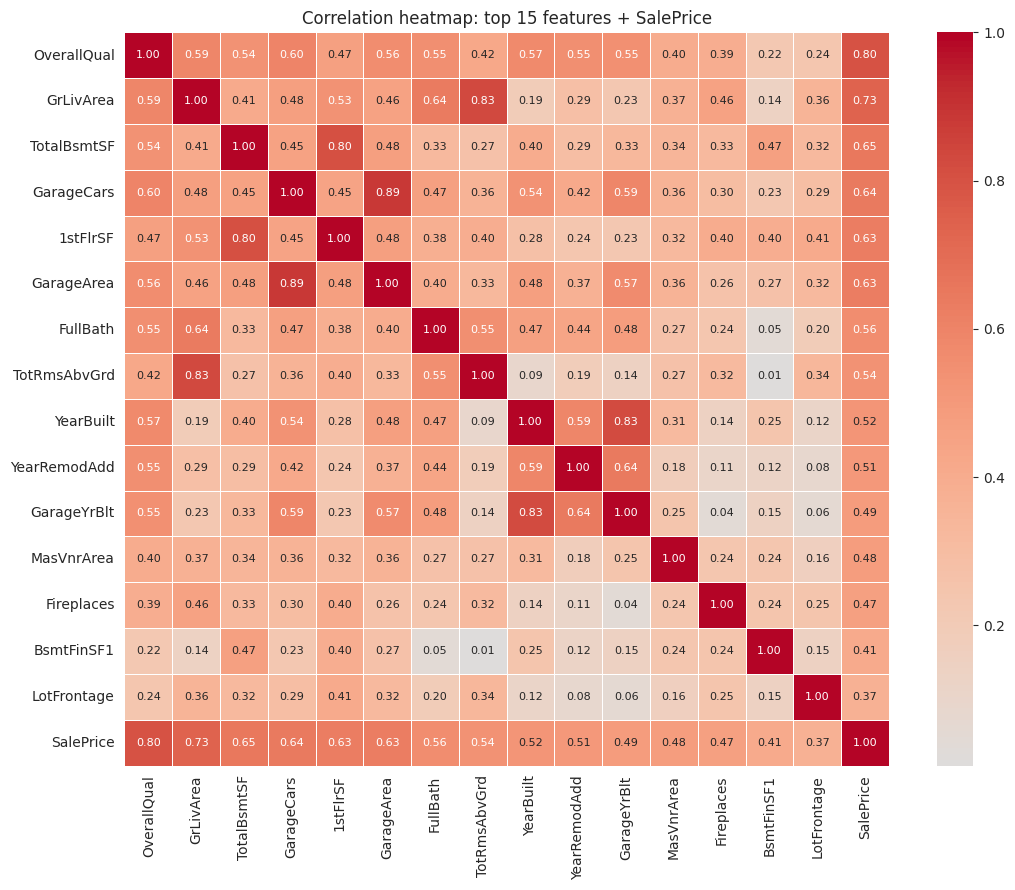


HIGHLY CORRELATED FEATURE PAIRS (|r| > 0.8)
GarageCars     <-> GarageArea     r = 0.887 | stronger link to target: GarageCars
GrLivArea      <-> TotRmsAbvGrd   r = 0.829 | stronger link to target: GrLivArea
YearBuilt      <-> GarageYrBlt    r = 0.825 | stronger link to target: YearBuilt
TotalBsmtSF    <-> 1stFlrSF       r = 0.804 | stronger link to target: TotalBsmtSF

Note: tree models handle redundancy well; linear models rely on regularization (Ridge/Lasso).


In [9]:
# ============================================================
# CELL 6: EDA - FEATURE CORRELATIONS
# Read-only. Safe to re-run. Uses the outlier-free train set.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_NO_OUTLIERS = f"{WORKING_DIR}/ckpt_01_train_no_outliers.pkl"

# Use the Cell 5 checkpoint, or rebuild it from the raw file
if os.path.exists(CKPT_NO_OUTLIERS):
    train = pd.read_pickle(CKPT_NO_OUTLIERS)["train"]
else:
    CANDIDATE_DIRS = [
        "/kaggle/input/house-prices-advanced-regression-techniques",
        "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
    ]
    INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
    if INPUT_DIR is None:
        raise FileNotFoundError("train.csv not found. Re-run Cell 2 and check the data is attached.")
    raw = pd.read_csv(f"{INPUT_DIR}/train.csv")
    train = raw.loc[~((raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000))].reset_index(drop=True)
print(f"Train rows used: {len(train)}")

# ---------- Correlations with the target ----------
num = train.select_dtypes(include=[np.number]).drop(columns=["Id"])
corr_price = num.drop(columns=["SalePrice"]).corrwith(num["SalePrice"])
corr_log   = num.drop(columns=["SalePrice"]).corrwith(np.log1p(num["SalePrice"]))

top15 = corr_price.abs().sort_values(ascending=False).head(15).index.tolist()
table = pd.DataFrame({"corr_SalePrice": corr_price[top15], "corr_log1p": corr_log[top15]})

print("=" * 55)
print("TOP 15 NUMERIC FEATURES BY |CORRELATION| WITH SalePrice")
print("=" * 55)
print(table.round(3).to_string())

print("\nStrongest NEGATIVE correlations:")
print(corr_price.sort_values().head(4).round(3).to_string())

# ---------- Heatmap ----------
heat_cols = top15 + ["SalePrice"]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(num[heat_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 8}, linewidths=0.4, ax=ax)
ax.set_title("Correlation heatmap: top 15 features + SalePrice")
plt.tight_layout()
plt.show()

# ---------- Highly correlated feature pairs ----------
feat_corr = num.drop(columns=["SalePrice"]).corr().abs()
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
pairs = (upper.stack().reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_corr"})
         .query("abs_corr > 0.8").sort_values("abs_corr", ascending=False))

print("\n" + "=" * 55)
print("HIGHLY CORRELATED FEATURE PAIRS (|r| > 0.8)")
print("=" * 55)
for _, r in pairs.iterrows():
    keep = r.feature_1 if abs(corr_price[r.feature_1]) >= abs(corr_price[r.feature_2]) else r.feature_2
    print(f"{r.feature_1:<14} <-> {r.feature_2:<14} r = {r.abs_corr:.3f} | "
          f"stronger link to target: {keep}")
print("\nNote: tree models handle redundancy well; linear models rely on regularization (Ridge/Lasso).")

## Cell 7: EDA, Categorical Analysis
- Median price by `OverallQual`, `Neighborhood` and `MSZoning` (the guide says "churn rate", but for house prices the right measure is median `SalePrice`)
- Rank all categorical features by how much of the log-price variance they explain (η²)
- Box plots for the top 5, and a cardinality table to flag high-cardinality features for target encoding

Train rows used: 1458
MEDIAN SalePrice BY OverallQual
               median  count
OverallQual                 
1             50150.0      2
2             60000.0      3
3             86250.0     20
4            108000.0    116
5            133000.0    397
6            160000.0    374
7            200141.0    319
8            269750.0    168
9            345000.0     43
10           445365.0     16

MEDIAN SalePrice BY MSZoning
            median  count
MSZoning                 
C (all)    74700.0     10
RM        120500.0    218
RH        136500.0     16
RL        174000.0   1149
FV        205950.0     65

NEIGHBORHOOD: 3 CHEAPEST & 3 MOST EXPENSIVE (median)
                median  count
Neighborhood                 
MeadowV        88000.0     17
IDOTRR        103000.0     37
BrDale        106000.0     16
StoneBr       278000.0     25
NoRidge       301500.0     41
NridgHt       315000.0     77

TOP 12 CATEGORICAL FEATURES BY ETA-SQUARED (log price)
              eta_sq  n_levels
Neigh

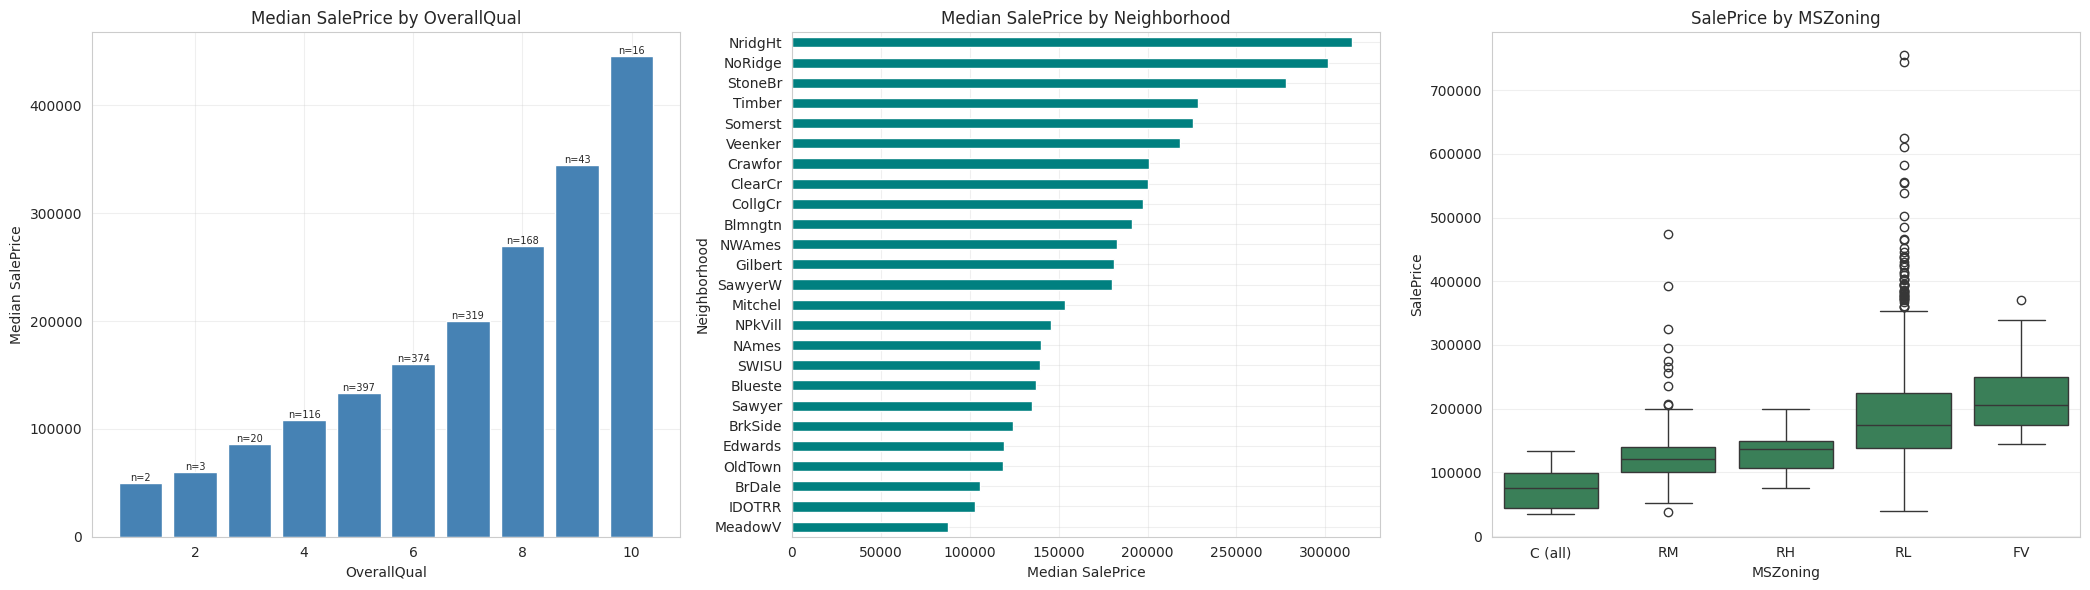

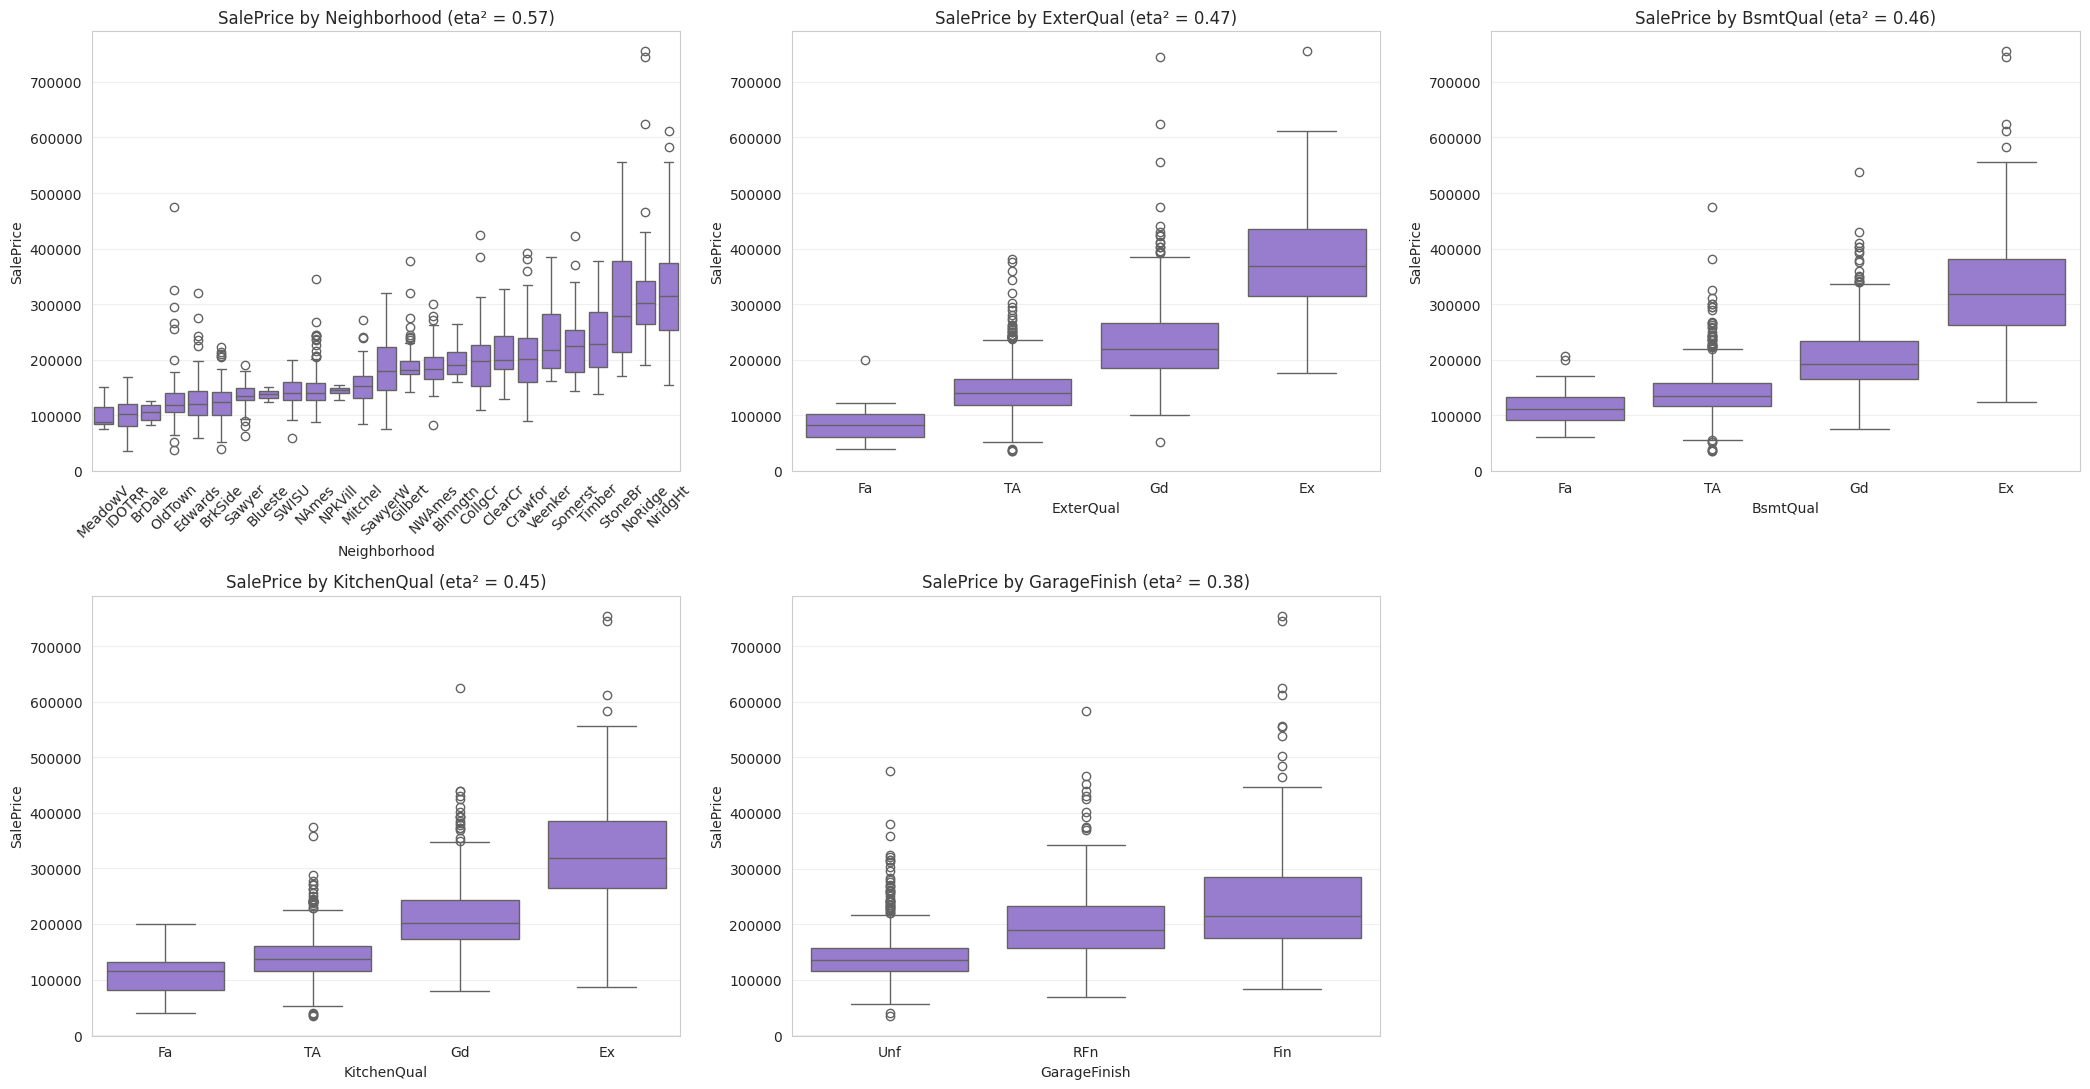

TAKEAWAYS
- Strongest categorical drivers: Neighborhood, ExterQual, BsmtQual, KitchenQual, GarageFinish.
- Price rises steadily with OverallQual (median 50,150 -> 445,365).
- 5 categoricals have > 8 levels -> candidates for target encoding (Cell 15).


In [10]:
# ============================================================
# CELL 7: EDA - CATEGORICAL ANALYSIS
# Read-only. Safe to re-run. Uses the outlier-free train set.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_NO_OUTLIERS = f"{WORKING_DIR}/ckpt_01_train_no_outliers.pkl"

if os.path.exists(CKPT_NO_OUTLIERS):
    train = pd.read_pickle(CKPT_NO_OUTLIERS)["train"]
else:
    CANDIDATE_DIRS = [
        "/kaggle/input/house-prices-advanced-regression-techniques",
        "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
    ]
    INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
    if INPUT_DIR is None:
        raise FileNotFoundError("train.csv not found. Re-run Cell 2 and check the data is attached.")
    raw = pd.read_csv(f"{INPUT_DIR}/train.csv")
    train = raw.loc[~((raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000))].reset_index(drop=True)
print(f"Train rows used: {len(train)}")

sns.set_style("whitegrid")
y_log = np.log1p(train["SalePrice"])

# ---------- Median price by key features ----------
print("=" * 55)
print("MEDIAN SalePrice BY OverallQual")
print("=" * 55)
oq = train.groupby("OverallQual")["SalePrice"].agg(median="median", count="count")
print(oq.to_string())

print("\n" + "=" * 55)
print("MEDIAN SalePrice BY MSZoning")
print("=" * 55)
print(train.groupby("MSZoning")["SalePrice"].agg(median="median", count="count")
      .sort_values("median").to_string())

nb = train.groupby("Neighborhood")["SalePrice"].agg(median="median", count="count").sort_values("median")
print("\n" + "=" * 55)
print("NEIGHBORHOOD: 3 CHEAPEST & 3 MOST EXPENSIVE (median)")
print("=" * 55)
print(pd.concat([nb.head(3), nb.tail(3)]).to_string())

# ---------- Eta-squared: share of log-price variance explained by each categorical ----------
def eta_squared(col):
    groups = y_log.groupby(train[col].fillna("None"))
    ss_between = sum(len(g) * (g.mean() - y_log.mean()) ** 2 for _, g in groups)
    ss_total = ((y_log - y_log.mean()) ** 2).sum()
    return ss_between / ss_total

obj_cols = train.drop(columns=["Id", "SalePrice"]).select_dtypes(exclude=[np.number]).columns.tolist()
eta = pd.Series({c: eta_squared(c) for c in obj_cols}).sort_values(ascending=False)
card = train[obj_cols].nunique()

print("\n" + "=" * 55)
print("TOP 12 CATEGORICAL FEATURES BY ETA-SQUARED (log price)")
print("=" * 55)
print(pd.DataFrame({"eta_sq": eta.head(12).round(3), "n_levels": card[eta.head(12).index]}).to_string())

# ---------- Cardinality ----------
high_card = card[card > 8].sort_values(ascending=False)
print("\n" + "=" * 55)
print("HIGH-CARDINALITY CATEGORICALS (> 8 levels)")
print("=" * 55)
print(high_card.to_string())
print("-> MSSubClass (15 levels) is numeric-coded but also high-cardinality.")

# ---------- Figure 1: three key relationships ----------
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

axes[0].bar(oq.index, oq["median"], color="steelblue")
for x, (m, c) in zip(oq.index, oq.values):
    axes[0].text(x, m, f"n={int(c)}", ha="center", va="bottom", fontsize=7)
axes[0].set_title("Median SalePrice by OverallQual")
axes[0].set_xlabel("OverallQual"); axes[0].set_ylabel("Median SalePrice")

nb["median"].plot(kind="barh", ax=axes[1], color="teal")
axes[1].set_title("Median SalePrice by Neighborhood")
axes[1].set_xlabel("Median SalePrice")

order = train.groupby("MSZoning")["SalePrice"].median().sort_values().index
sns.boxplot(data=train, x="MSZoning", y="SalePrice", order=order, color="seagreen", ax=axes[2])
axes[2].set_title("SalePrice by MSZoning")
plt.tight_layout()
plt.show()

# ---------- Figure 2: box plots of the top 5 categorical features ----------
top5 = eta.head(5).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(21, 11))
for ax, col in zip(axes.ravel(), top5):
    order = train.groupby(col)["SalePrice"].median().sort_values().index
    sns.boxplot(data=train, x=col, y="SalePrice", order=order, color="mediumpurple", ax=ax)
    ax.set_title(f"SalePrice by {col} (eta² = {eta[col]:.2f})")
    ax.tick_params(axis="x", rotation=45 if card[col] > 6 else 0)
axes.ravel()[5].axis("off")
plt.tight_layout()
plt.show()

print("=" * 55)
print("TAKEAWAYS")
print("=" * 55)
print(f"- Strongest categorical drivers: {', '.join(top5)}.")
print(f"- Price rises steadily with OverallQual (median {oq['median'].iloc[0]:,.0f} -> {oq['median'].iloc[-1]:,.0f}).")
print(f"- {len(high_card)} categoricals have > 8 levels -> candidates for target encoding (Cell 15).")

## Cell 8: EDA, Missing Values
- Count missing values per column in **train and test**, and draw a missing-value heatmap
- Classify each NA as **absent feature** (e.g. no pool) or **genuinely missing** (data gap), with the planned fix
- Check that garage and basement NAs line up across related columns (evidence for "absent")

MISSING VALUES
Columns with NA -> train: 19 | test: 33 | either: 34
      column  train_NA  test_NA              type                     strategy
      PoolQC      1452     1456    absent feature                       'None'
 MiscFeature      1404     1408    absent feature                       'None'
       Alley      1367     1352    absent feature                       'None'
       Fence      1177     1169    absent feature                       'None'
  MasVnrType       872      894    absent feature                       'None'
 FireplaceQu       690      730    absent feature                       'None'
 LotFrontage       259      227 genuinely missing       median by Neighborhood
GarageFinish        81       78    absent feature                       'None'
  GarageCond        81       78    absent feature                       'None'
 GarageYrBlt        81       78    absent feature                            0
  GarageQual        81       78    absent feature              

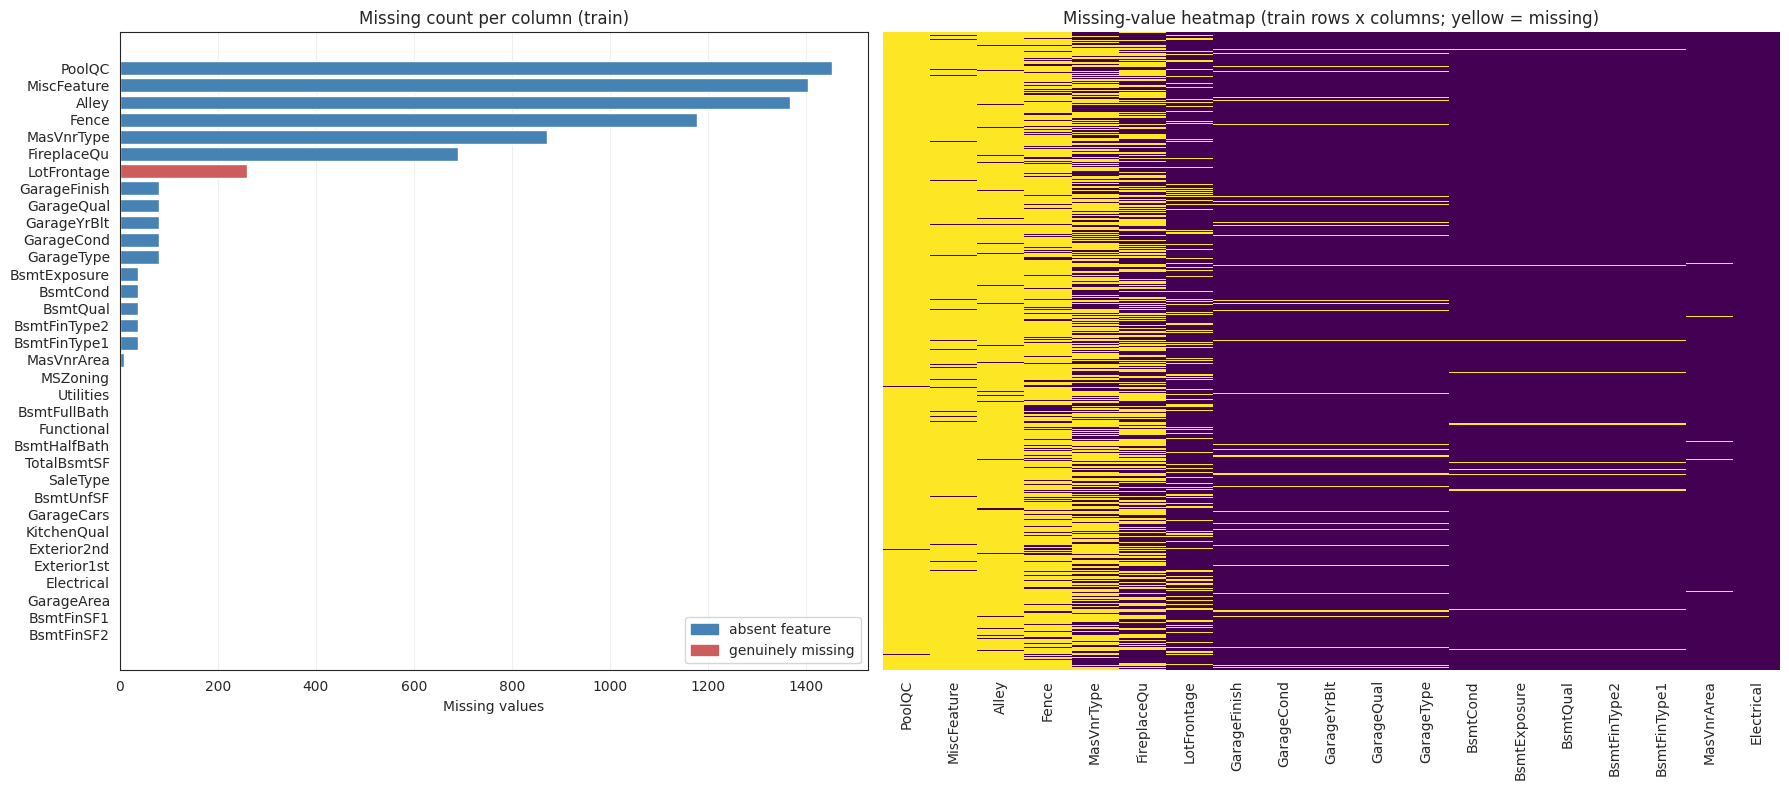

Rule used: absent feature -> fill with 'None'/0 | genuinely missing -> statistic from TRAIN only.


In [11]:
# ============================================================
# CELL 8: EDA - MISSING VALUES
# Read-only. Safe to re-run.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_NO_OUTLIERS = f"{WORKING_DIR}/ckpt_01_train_no_outliers.pkl"

CANDIDATE_DIRS = [
    "/kaggle/input/house-prices-advanced-regression-techniques",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
]
INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
if INPUT_DIR is None:
    raise FileNotFoundError("train.csv not found. Re-run Cell 2 and check the data is attached.")
test = pd.read_csv(f"{INPUT_DIR}/test.csv")
if os.path.exists(CKPT_NO_OUTLIERS):
    train = pd.read_pickle(CKPT_NO_OUTLIERS)["train"]
else:
    raw = pd.read_csv(f"{INPUT_DIR}/train.csv")
    train = raw.loc[~((raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000))].reset_index(drop=True)

sns.set_style("white")

# ---------- Classification: absent feature vs genuinely missing ----------
ABSENT_CATEGORICAL = [   # NA means the house has no such feature -> "None"
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]
ABSENT_NUMERIC = [       # NA means no garage / basement / veneer -> 0
    "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath",
]
STRATEGY_GENUINE = {
    "LotFrontage": "median by Neighborhood",
    "Electrical": "mode",
    "MSZoning": "mode", "Utilities": "mode", "KitchenQual": "mode",
    "Exterior1st": "mode", "Exterior2nd": "mode", "SaleType": "mode",
    "Functional": "'Typ' (per data_description)",
}

miss_train = train.drop(columns=["SalePrice"]).isna().sum()
miss_test  = test.isna().sum()
cols_missing = sorted(set(miss_train[miss_train > 0].index) | set(miss_test[miss_test > 0].index))

rows = []
for c in cols_missing:
    if c in ABSENT_CATEGORICAL:
        kind, strat = "absent feature", "'None'"
    elif c in ABSENT_NUMERIC:
        kind, strat = "absent feature", "0"
    else:
        kind, strat = "genuinely missing", STRATEGY_GENUINE.get(c, "mode / median (fallback)")
    rows.append({"column": c, "train_NA": int(miss_train[c]), "test_NA": int(miss_test[c]),
                 "type": kind, "strategy": strat})
table = (pd.DataFrame(rows).assign(total=lambda d: d.train_NA + d.test_NA)
         .sort_values("total", ascending=False).drop(columns="total").reset_index(drop=True))

print("=" * 55)
print("MISSING VALUES")
print("=" * 55)
print(f"Columns with NA -> train: {(miss_train > 0).sum()} | test: {(miss_test > 0).sum()} | "
      f"either: {len(cols_missing)}")
print(table.to_string(index=False))
print(f"\nBy type: {table['type'].value_counts().to_dict()}")

# ---------- Evidence: related NA columns line up ----------
print("\n" + "=" * 55)
print("CONSISTENCY CHECK (train): NA counts across related columns")
print("=" * 55)
for label, cols in [("Garage", ["GarageType", "GarageFinish", "GarageQual", "GarageCond", "GarageYrBlt"]),
                    ("Basement", ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"])]:
    counts = {c: int(train[c].isna().sum()) for c in cols}
    print(f"{label}: {counts}")
print("-> Garage NAs match exactly (no garage). Basement counts differ by 1 row "
      "(BsmtExposure / BsmtFinType2 have one genuine gap).")

# ---------- Plots ----------
colors = {"absent feature": "steelblue", "genuinely missing": "indianred"}
plot_df = table.assign(total=lambda d: d.train_NA + d.test_NA).sort_values("total")
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1, 1.2]})

axes[0].barh(plot_df["column"], plot_df["train_NA"], color=[colors[t] for t in plot_df["type"]])
axes[0].set_title("Missing count per column (train)")
axes[0].set_xlabel("Missing values")
axes[0].grid(axis="x", alpha=0.3)
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=v, label=k) for k, v in colors.items()], loc="lower right")

train_cols = [c for c in table["column"] if miss_train[c] > 0]
sns.heatmap(train[train_cols].isna(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[1])
axes[1].set_title("Missing-value heatmap (train rows x columns; yellow = missing)")
plt.tight_layout()
plt.show()

print("Rule used: absent feature -> fill with 'None'/0 | genuinely missing -> statistic from TRAIN only.")

## Cell 9: EDA, Near-Constant Features
- Find features where one value covers more than 95% of train rows
- Inspect `Utilities` and `Street`, and decide which to drop (the guide drops `Utilities`, `Street` and `Id`)

NEAR-CONSTANT FEATURES (one value in > 95% of train rows)
             top_value  top_freq_pct  n_unique
feature                                       
Utilities       AllPub         99.93         2
Street            Pave         99.59         2
PoolArea             0         99.59         7
PoolQC             nan         99.59         3
Condition2        Norm         99.04         8
3SsnPorch            0         98.35        20
RoofMatl       CompShg         98.29         7
LowQualFinSF         0         98.22        24
Heating           GasA         97.81         6
MiscVal              0         96.43        21
MiscFeature        nan         96.30         4
KitchenAbvGr         1         95.34         4

UTILITIES & STREET
Utilities (train): {'AllPub': 1457, 'NoSeWa': 1}
Utilities (test) : {'AllPub': 1457, nan: 2}
Street (train): {'Pave': 1452, 'Grvl': 6}
Street (test) : {'Pave': 1453, 'Grvl': 6}
-> Utilities: all 'AllPub' except one train row, and test has no 'NoSeWa' at all,
   so

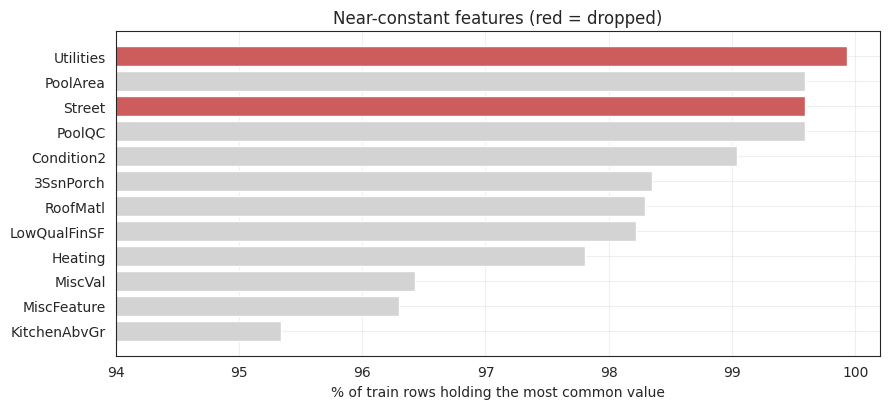

DECISION
Drop: ['Utilities', 'Street'] (+ Id in Cell 13)
Flagged but kept (10): ['PoolArea', 'PoolQC', 'Condition2', '3SsnPorch', 'RoofMatl', 'LowQualFinSF', 'Heating', 'MiscVal', 'MiscFeature', 'KitchenAbvGr']
-> Kept features may still matter (e.g. PoolArea, 3SsnPorch flag rare but real features);
   regularization and tree splits handle them, and Cell 16 re-checks one-hot columns.


In [12]:
# ============================================================
# CELL 9: EDA - NEAR-CONSTANT FEATURES (fixed)
# Read-only. Safe to re-run.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_NO_OUTLIERS = f"{WORKING_DIR}/ckpt_01_train_no_outliers.pkl"

CANDIDATE_DIRS = [
    "/kaggle/input/house-prices-advanced-regression-techniques",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
]
INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
if INPUT_DIR is None:
    raise FileNotFoundError("train.csv not found. Re-run Cell 2 and check the data is attached.")
test = pd.read_csv(f"{INPUT_DIR}/test.csv")
if os.path.exists(CKPT_NO_OUTLIERS):
    train = pd.read_pickle(CKPT_NO_OUTLIERS)["train"]
else:
    raw = pd.read_csv(f"{INPUT_DIR}/train.csv")
    train = raw.loc[~((raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000))].reset_index(drop=True)

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ---------- Most common value per column (loop avoids mixed-type sorting errors) ----------
feat = train.drop(columns=["Id", "SalePrice"])
rows = []
for col in feat.columns:
    counts = feat[col].value_counts(dropna=False)
    rows.append({
        "feature": col,
        "top_value": str(counts.index[0]),
        "top_freq_pct": round(counts.iloc[0] / len(feat) * 100, 2),
        "n_unique": int(feat[col].nunique()),
    })
nc = pd.DataFrame(rows).set_index("feature")
flagged = nc[nc["top_freq_pct"] > 95].sort_values("top_freq_pct", ascending=False)

print("=" * 55)
print("NEAR-CONSTANT FEATURES (one value in > 95% of train rows)")
print("=" * 55)
print(flagged.to_string())

# ---------- The two the guide names ----------
print("\n" + "=" * 55)
print("UTILITIES & STREET")
print("=" * 55)
for col in ["Utilities", "Street"]:
    print(f"{col} (train): {train[col].value_counts(dropna=False).to_dict()}")
    print(f"{col} (test) : {test[col].value_counts(dropna=False).to_dict()}")
print("-> Utilities: all 'AllPub' except one train row, and test has no 'NoSeWa' at all,")
print("   so it carries no usable signal. Street: ~99.6% 'Pave'.")

# ---------- Does the rare value matter? ----------
y_log = np.log1p(train["SalePrice"])
print("\nMean log1p(SalePrice) by level:")
for col in ["Utilities", "Street"]:
    print(f"{col}: {y_log.groupby(train[col]).agg(['mean', 'count']).round(3).to_dict('index')}")

# ---------- Plot ----------
plot_df = flagged["top_freq_pct"].sort_values()
bar_colors = ["indianred" if c in ("Utilities", "Street") else "lightgray" for c in plot_df.index]
fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(plot_df))))
ax.barh(plot_df.index, plot_df.values, color=bar_colors)
ax.set_xlim(94, 100.2)
ax.set_xlabel("% of train rows holding the most common value")
ax.set_title("Near-constant features (red = dropped)")
plt.tight_layout()
plt.show()

# ---------- Decision ----------
DROP_NEAR_CONSTANT = ["Utilities", "Street"]
others = [c for c in flagged.index if c not in DROP_NEAR_CONSTANT]
print("=" * 55)
print("DECISION")
print("=" * 55)
print(f"Drop: {DROP_NEAR_CONSTANT} (+ Id in Cell 13)")
print(f"Flagged but kept ({len(others)}): {others}")
print("-> Kept features may still matter (e.g. PoolArea, 3SsnPorch flag rare but real features);")
print("   regularization and tree splits handle them, and Cell 16 re-checks one-hot columns.")

## Cell 10: EDA Findings & Action Plan

| Finding | Evidence | Action |
|---|---|---|
| **Outliers** | 2 houses with `GrLivArea > 4000` sold for under $300K (Ids 524 and 1299) | Removed (Cell 5) |
| **Target skew** | `SalePrice` skew 1.88, `log1p` skew 0.12 | Train on `log1p(SalePrice)`, `expm1` at the end |
| **Missing values** | 19 columns in train, 33 in test; most NAs mean "feature absent" | `"None"` / 0 for absent features, median or mode for genuine gaps (Cell 11) |
| **Near-constant features** | `Utilities` and `Street` hold one value in about 99.6–99.9% of rows | Drop with `Id` (Cell 13) |
| **Ordinal features** | Quality/condition scales (Po→Ex, Unf→GLQ, ...) | Integer-map in natural order (Cell 14) |
| **High-cardinality features** | `Neighborhood`, `Exterior1st`, `Exterior2nd` (> 8 levels) | K-fold target encoding (Cell 15) |
| **Remaining nominal features** | Low-cardinality categoricals | One-hot encode (Cell 16) |
| **Skewed numeric features** | Areas and porch sizes are right-skewed | `log1p` where \|skew\| > 0.75 (Cell 17) |
| **Strongest signals** | `OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `Neighborhood` | Build `TotalSF`, `OverallScore`, `QualAreaScore` (Cell 12) |

In [13]:
# ============================================================
# CELL 10 (companion code): ACTION PLAN CHECKLIST
# Prints the plan; no data is touched. Safe to re-run.
# ============================================================
plan = [
    ("Cell 11", "Missing values",        "'None'/0 for absent features; median/mode (train stats) for gaps; verify 0 NaN"),
    ("Cell 12", "Feature engineering",   "TotalSF, TotalBaths, AgeAtSale, AgeRemod, TotalPorchSF, OverallScore, QualAreaScore, 8 binary flags"),
    ("Cell 13", "Drop features",         "Utilities, Street, Id"),
    ("Cell 14", "Ordinal encoding",      "integer maps for 15+ quality/condition features"),
    ("Cell 15", "Target encoding",       "Neighborhood, Exterior1st, Exterior2nd (k-fold, no leakage)"),
    ("Cell 16", "One-hot encoding",      "remaining nominal features; align train/test columns"),
    ("Cell 17", "Skewness correction",   "log1p where |skew| > 0.75 (skew measured on train)"),
    ("Cell 18", "Target transformation", "log1p(SalePrice)"),
]
print("=" * 70)
print("ACTION PLAN")
print("=" * 70)
for cell, step, detail in plan:
    print(f"{cell:<8} {step:<22} {detail}")

ACTION PLAN
Cell 11  Missing values         'None'/0 for absent features; median/mode (train stats) for gaps; verify 0 NaN
Cell 12  Feature engineering    TotalSF, TotalBaths, AgeAtSale, AgeRemod, TotalPorchSF, OverallScore, QualAreaScore, 8 binary flags
Cell 13  Drop features          Utilities, Street, Id
Cell 14  Ordinal encoding       integer maps for 15+ quality/condition features
Cell 15  Target encoding        Neighborhood, Exterior1st, Exterior2nd (k-fold, no leakage)
Cell 16  One-hot encoding       remaining nominal features; align train/test columns
Cell 17  Skewness correction    log1p where |skew| > 0.75 (skew measured on train)
Cell 18  Target transformation  log1p(SalePrice)


## Cell 11: Missing Value Handling
- Apply the strategy from Cell 8: `"None"` / `0` for absent features, train-only median or mode for genuine gaps
- Fix the impossible `GarageYrBlt` value (2207) in test
- Print before/after NA counts, verify zero nulls, and save `ckpt_02_clean.pkl`

In [14]:
# ============================================================
# CELL 11: MISSING VALUE HANDLING
# Safe to re-run. Raw data is never modified; saves a checkpoint.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
os.makedirs(WORKING_DIR, exist_ok=True)
CKPT_NO_OUTLIERS = f"{WORKING_DIR}/ckpt_01_train_no_outliers.pkl"
CKPT_CLEAN       = f"{WORKING_DIR}/ckpt_02_clean.pkl"

CANDIDATE_DIRS = [
    "/kaggle/input/house-prices-advanced-regression-techniques",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
]
INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
if INPUT_DIR is None:
    raise FileNotFoundError("train.csv not found. Re-run Cell 2 and check the data is attached.")
test_raw = pd.read_csv(f"{INPUT_DIR}/test.csv")
if os.path.exists(CKPT_NO_OUTLIERS):
    train_in = pd.read_pickle(CKPT_NO_OUTLIERS)["train"]
else:
    raw = pd.read_csv(f"{INPUT_DIR}/train.csv")
    train_in = raw.loc[~((raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000))].reset_index(drop=True)
print(f"Train rows: {len(train_in)} | test rows: {len(test_raw)}")

# ---------- Strategy ----------
NONE_COLS = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]
ZERO_COLS = [
    "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath",
]
MODE_COLS = ["MSZoning", "Electrical", "KitchenQual", "Exterior1st",
             "Exterior2nd", "SaleType", "Utilities"]

# ---------- Statistics from TRAIN only ----------
stats = {
    "lf_by_nb":  train_in.groupby("Neighborhood")["LotFrontage"].median(),
    "lf_global": train_in["LotFrontage"].median(),
    "modes":     {c: train_in[c].mode()[0] for c in MODE_COLS},
    "num_median": train_in.select_dtypes(include=[np.number]).median(),
    "cat_mode":  {c: train_in[c].mode()[0]
                  for c in train_in.select_dtypes(exclude=[np.number]).columns},
}

def impute(df):
    out = df.copy()
    for c in NONE_COLS:
        out[c] = out[c].fillna("None")
    for c in ZERO_COLS:
        out[c] = out[c].fillna(0)
    out["Functional"] = out["Functional"].fillna("Typ")          # per data_description.txt
    for c, m in stats["modes"].items():
        out[c] = out[c].fillna(m)
    out["LotFrontage"] = (out["LotFrontage"]
                          .fillna(out["Neighborhood"].map(stats["lf_by_nb"]))
                          .fillna(stats["lf_global"]))
    fallback = []                                                 # safety net
    for c in out.columns:
        if c == "SalePrice" or not out[c].isna().any():
            continue
        fallback.append(c)
        out[c] = out[c].fillna(stats["num_median"][c] if pd.api.types.is_numeric_dtype(out[c])
                               else stats["cat_mode"][c])
    # Impossible garage year (one test row has 2207) -> year the house was built
    bad = out["GarageYrBlt"] > 2010
    out.loc[bad, "GarageYrBlt"] = out.loc[bad, "YearBuilt"]
    return out, fallback, int(bad.sum())

train_clean, fb_tr, fix_tr = impute(train_in)
test_clean,  fb_te, fix_te = impute(test_raw)

# ---------- Before / after ----------
before_tr = train_in.drop(columns=["SalePrice"]).isna().sum()
before_te = test_raw.isna().sum()
cols = sorted(set(before_tr[before_tr > 0].index) | set(before_te[before_te > 0].index))
report = pd.DataFrame({
    "train_before": before_tr.reindex(cols).fillna(0).astype(int),
    "train_after":  train_clean[cols].isna().sum(),
    "test_before":  before_te.reindex(cols).fillna(0).astype(int),
    "test_after":   test_clean[cols].isna().sum(),
}).sort_values("train_before", ascending=False)

print("\n" + "=" * 55)
print("NULL COUNTS: BEFORE -> AFTER")
print("=" * 55)
print(report.to_string())
print(f"\nColumns with NA -> train: {(before_tr > 0).sum()} -> "
      f"{int((train_clean.drop(columns=['SalePrice']).isna().sum() > 0).sum())} | "
      f"test: {(before_te > 0).sum()} -> {int((test_clean.isna().sum() > 0).sum())}")
print(f"Fallback imputation used -> train: {fb_tr or 'none'} | test: {fb_te or 'none'}")
print(f"GarageYrBlt fixed (>2010) -> train: {fix_tr} | test: {fix_te}")

# ---------- Verification ----------
assert train_clean.drop(columns=["SalePrice"]).isna().sum().sum() == 0, "train still has NaN"
assert test_clean.isna().sum().sum() == 0, "test still has NaN"
assert list(train_clean.drop(columns=["SalePrice"]).columns) == list(test_clean.columns), "column mismatch"
assert len(train_clean) == 1458 and len(test_clean) == 1459, "row count changed"
print("\nAll assertions passed: zero nulls in train and test.")
print(f"train_clean: {train_clean.shape} | test_clean: {test_clean.shape}")

# ---------- Checkpoint ----------
pd.to_pickle({"train": train_clean, "test": test_clean}, CKPT_CLEAN)
print(f"Saved {os.path.basename(CKPT_CLEAN)} ({os.path.getsize(CKPT_CLEAN)/1024:.0f} KB)")

Train rows: 1458 | test rows: 1459

NULL COUNTS: BEFORE -> AFTER
              train_before  train_after  test_before  test_after
PoolQC                1452            0         1456           0
MiscFeature           1404            0         1408           0
Alley                 1367            0         1352           0
Fence                 1177            0         1169           0
MasVnrType             872            0          894           0
FireplaceQu            690            0          730           0
LotFrontage            259            0          227           0
GarageFinish            81            0           78           0
GarageCond              81            0           78           0
GarageYrBlt             81            0           78           0
GarageType              81            0           76           0
GarageQual              81            0           78           0
BsmtFinType2            38            0           42           0
BsmtExposure            3

## Cell 12: Feature Engineering
- Create `TotalSF`, `TotalBaths`, `AgeAtSale`, `AgeRemod`, `TotalPorchSF`, `OverallScore` and `QualAreaScore`
- Add 8 binary indicators (`HasPool`, `Has2ndFloor`, `HasGarage`, `HasBasement`, `HasFireplace`, `HasPorch`, `IsRemodeled`, `IsNew`)
- Verify shapes and correlations, and save `ckpt_03_features.pkl`

In [15]:
# ============================================================
# CELL 12: FEATURE ENGINEERING
# Safe to re-run. Loads the Cell 11 checkpoint.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_CLEAN    = f"{WORKING_DIR}/ckpt_02_clean.pkl"
CKPT_FEATURES = f"{WORKING_DIR}/ckpt_03_features.pkl"

if not os.path.exists(CKPT_CLEAN):
    raise FileNotFoundError("ckpt_02_clean.pkl missing. Re-run Cell 11 first.")
d = pd.read_pickle(CKPT_CLEAN)
train_clean, test_clean = d["train"], d["test"]

NEW_NUMERIC = ["TotalSF", "TotalBaths", "AgeAtSale", "AgeRemod", "TotalPorchSF",
               "OverallScore", "QualAreaScore"]
NEW_BINARY  = ["HasPool", "Has2ndFloor", "HasGarage", "HasBasement", "HasFireplace",
               "HasPorch", "IsRemodeled", "IsNew"]
NEW_FEATS = NEW_NUMERIC + NEW_BINARY

def add_features(df):
    """Row-wise transforms only (no statistics are learned), so train and test use the same code."""
    out = df.copy()
    out["TotalSF"]       = out["TotalBsmtSF"] + out["1stFlrSF"] + out["2ndFlrSF"]
    out["TotalBaths"]    = (out["FullBath"] + 0.5 * out["HalfBath"]
                            + out["BsmtFullBath"] + 0.5 * out["BsmtHalfBath"])
    out["AgeAtSale"]     = (out["YrSold"] - out["YearBuilt"]).clip(lower=0)
    out["AgeRemod"]      = (out["YrSold"] - out["YearRemodAdd"]).clip(lower=0)
    out["TotalPorchSF"]  = (out["OpenPorchSF"] + out["EnclosedPorch"] + out["3SsnPorch"]
                            + out["ScreenPorch"] + out["WoodDeckSF"])
    out["OverallScore"]  = out["OverallQual"] * out["OverallCond"]
    out["QualAreaScore"] = out["OverallQual"] * out["GrLivArea"]

    out["HasPool"]       = (out["PoolArea"] > 0).astype(int)
    out["Has2ndFloor"]   = (out["2ndFlrSF"] > 0).astype(int)
    out["HasGarage"]     = (out["GarageArea"] > 0).astype(int)
    out["HasBasement"]   = (out["TotalBsmtSF"] > 0).astype(int)
    out["HasFireplace"]  = (out["Fireplaces"] > 0).astype(int)
    out["HasPorch"]      = (out["TotalPorchSF"] > 0).astype(int)
    out["IsRemodeled"]   = (out["YearRemodAdd"] != out["YearBuilt"]).astype(int)
    out["IsNew"]         = (out["YearBuilt"] == out["YrSold"]).astype(int)
    return out

train_fe = add_features(train_clean)
test_fe  = add_features(test_clean)

# ---------- Verify shapes ----------
print("=" * 55)
print("SHAPES")
print("=" * 55)
print(f"train: {train_clean.shape} -> {train_fe.shape} (+{train_fe.shape[1] - train_clean.shape[1]})")
print(f"test : {test_clean.shape} -> {test_fe.shape} (+{test_fe.shape[1] - test_clean.shape[1]})")

assert train_fe.shape[1] - train_clean.shape[1] == len(NEW_FEATS) == 15, "Wrong number of new features"
assert list(train_fe.drop(columns=["SalePrice"]).columns) == list(test_fe.columns), "Column mismatch"
assert train_fe[NEW_FEATS].isna().sum().sum() == 0 and test_fe[NEW_FEATS].isna().sum().sum() == 0, "NaN in new features"
assert np.isfinite(train_fe[NEW_FEATS].values).all() and np.isfinite(test_fe[NEW_FEATS].values).all(), "inf in new features"
assert len(train_fe) == 1458 and len(test_fe) == 1459, "Row count changed"
print("All assertions passed.")

# ---------- Summaries ----------
print("\n" + "=" * 55)
print("NEW NUMERIC FEATURES (train)")
print("=" * 55)
print(train_fe[NEW_NUMERIC].describe().loc[["mean", "min", "50%", "max"]].round(2).to_string())

print("\n" + "=" * 55)
print("BINARY FLAGS: rows with flag = 1 (train / test)")
print("=" * 55)
for c in NEW_BINARY:
    print(f"{c:<13} {int(train_fe[c].sum()):>5} / {int(test_fe[c].sum()):>5}")

# ---------- Correlation with log target ----------
y_log = np.log1p(train_fe["SalePrice"])
corr = train_fe[NEW_FEATS].corrwith(y_log).sort_values(ascending=False)
print("\n" + "=" * 55)
print("NEW FEATURES vs log1p(SalePrice)")
print("=" * 55)
print(corr.round(3).to_string())
print(f"\nFor reference: OverallQual r = {train_fe['OverallQual'].corr(y_log):.3f}, "
      f"GrLivArea r = {train_fe['GrLivArea'].corr(y_log):.3f}")
print("Note: HasPool is nearly constant (~7 pool houses); Cell 16 re-checks near-constant columns.")

# ---------- Checkpoint ----------
pd.to_pickle({"train": train_fe, "test": test_fe, "new_feats": NEW_FEATS}, CKPT_FEATURES)
print(f"\nSaved {os.path.basename(CKPT_FEATURES)} ({os.path.getsize(CKPT_FEATURES)/1024:.0f} KB)")

SHAPES
train: (1458, 81) -> (1458, 96) (+15)
test : (1459, 80) -> (1459, 95) (+15)
All assertions passed.

NEW NUMERIC FEATURES (train)
      TotalSF  TotalBaths  AgeAtSale  AgeRemod  TotalPorchSF  OverallScore  QualAreaScore
mean  2557.15        2.21       36.6     22.98        180.81         33.84        9616.46
min    334.00        1.00        0.0      0.00          0.00          1.00         334.00
50%   2473.00        2.00       35.0     14.00        164.00         35.00        8817.00
max   6872.00        6.00      136.0     60.00       1027.00         90.00       44760.00

BINARY FLAGS: rows with flag = 1 (train / test)
HasPool           6 /     6
Has2ndFloor     629 /   620
HasGarage      1377 /  1382
HasBasement    1421 /  1417
HasFireplace    768 /   729
HasPorch       1204 /  1231
IsRemodeled     695 /   663
IsNew            62 /    52

NEW FEATURES vs log1p(SalePrice)
QualAreaScore    0.838
TotalSF          0.825
TotalBaths       0.677
OverallScore     0.608
HasFireplace   

## Cell 13: Drop Near-Constant Features
- Drop `Utilities`, `Street` and `Id` (the decision from Cell 9)
- Keep the train and test `Id` values aside for the final submission
- Verify the remaining feature count and save `ckpt_04_dropped.pkl`

In [16]:
# ============================================================
# CELL 13: DROP NEAR-CONSTANT FEATURES (+ Id)
# Safe to re-run. Loads the Cell 12 checkpoint; never drops in place.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_FEATURES = f"{WORKING_DIR}/ckpt_03_features.pkl"
CKPT_DROPPED  = f"{WORKING_DIR}/ckpt_04_dropped.pkl"

if not os.path.exists(CKPT_FEATURES):
    raise FileNotFoundError("ckpt_03_features.pkl missing. Re-run Cells 11-12 first.")
d = pd.read_pickle(CKPT_FEATURES)
train_fe, test_fe, NEW_FEATS = d["train"], d["test"], d["new_feats"]

# Keep Ids aside (needed for submission.csv)
train_ids = train_fe["Id"].reset_index(drop=True)
test_ids  = test_fe["Id"].reset_index(drop=True)

# ---------- Drop (works even if a column is already gone) ----------
DROP_COLS = ["Utilities", "Street", "Id"]
train_d = train_fe.drop(columns=[c for c in DROP_COLS if c in train_fe.columns])
test_d  = test_fe.drop(columns=[c for c in DROP_COLS if c in test_fe.columns])

# ---------- Verify ----------
n_feat_train = train_d.drop(columns=["SalePrice"]).shape[1]
print("=" * 55)
print("FEATURE COUNT")
print("=" * 55)
print(f"Dropped: {DROP_COLS}")
print(f"train: {train_fe.shape} -> {train_d.shape} | features: {n_feat_train}")
print(f"test : {test_fe.shape} -> {test_d.shape} | features: {test_d.shape[1]}")
print(f"Original 79 - 2 dropped + {len(NEW_FEATS)} engineered = {79 - 2 + len(NEW_FEATS)}")

assert all(c not in train_d.columns and c not in test_d.columns for c in DROP_COLS), "Drop failed"
assert n_feat_train == test_d.shape[1] == 79 - 2 + len(NEW_FEATS), "Unexpected feature count"
assert list(train_d.drop(columns=["SalePrice"]).columns) == list(test_d.columns), "Column mismatch"
assert len(train_d) == len(train_ids) == 1458 and len(test_d) == len(test_ids) == 1459, "Row count changed"
print("All assertions passed.")

# ---------- Column type overview ----------
n_num = train_d.drop(columns=["SalePrice"]).select_dtypes(include=[np.number]).shape[1]
n_obj = train_d.drop(columns=["SalePrice"]).select_dtypes(exclude=[np.number]).shape[1]
print(f"\nNumeric features: {n_num} | Categorical (text) features: {n_obj}")

# ---------- Checkpoint ----------
pd.to_pickle({"train": train_d, "test": test_d, "train_ids": train_ids,
              "test_ids": test_ids, "new_feats": NEW_FEATS}, CKPT_DROPPED)
print(f"\nSaved {os.path.basename(CKPT_DROPPED)} ({os.path.getsize(CKPT_DROPPED)/1024:.0f} KB)")

FEATURE COUNT
Dropped: ['Utilities', 'Street', 'Id']
train: (1458, 96) -> (1458, 93) | features: 92
test : (1459, 95) -> (1459, 92) | features: 92
Original 79 - 2 dropped + 15 engineered = 92
All assertions passed.

Numeric features: 51 | Categorical (text) features: 41

Saved ckpt_04_dropped.pkl (1814 KB)


## Cell 14: Ordinal Encoding
- Map 20 ordered features (quality scales, exposure, finish, function, fence, etc.) to integers in their natural order
- `"None"` (feature absent) = 0, so absence ranks below the worst quality
- Verify no NaN after encoding, and save `ckpt_05_ordinal.pkl`

In [17]:
# ============================================================
# CELL 14: ORDINAL ENCODING
# Safe to re-run. Loads the Cell 13 checkpoint.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_DROPPED = f"{WORKING_DIR}/ckpt_04_dropped.pkl"
CKPT_ORDINAL = f"{WORKING_DIR}/ckpt_05_ordinal.pkl"

if not os.path.exists(CKPT_DROPPED):
    raise FileNotFoundError("ckpt_04_dropped.pkl missing. Re-run Cell 13 first.")
d = pd.read_pickle(CKPT_DROPPED)
train_d, test_d = d["train"], d["test"]

# ---------- Natural-order maps ----------
qual = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
bsmt_fin = {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}

ORDINAL_MAPS = {c: qual for c in [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
    "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]}
ORDINAL_MAPS.update({
    "BsmtExposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": bsmt_fin,
    "BsmtFinType2": bsmt_fin,
    "GarageFinish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Functional":   {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
    "LandSlope":    {"Sev": 1, "Mod": 2, "Gtl": 3},
    "LotShape":     {"IR3": 1, "IR2": 2, "IR1": 3, "Reg": 4},
    "PavedDrive":   {"N": 0, "P": 1, "Y": 2},
    "CentralAir":   {"N": 0, "Y": 1},
    "Fence":        {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
})

# Skip columns that are already numeric (safe if the cell is re-run on encoded data)
todo = [c for c in ORDINAL_MAPS if c in train_d.columns and train_d[c].dtype == object]
print(f"Ordinal features to encode: {len(todo)} of {len(ORDINAL_MAPS)}")

# ---------- Check for unmapped values BEFORE mapping ----------
for name, df in [("train", train_d), ("test", test_d)]:
    for c in todo:
        unknown = set(df[c].unique()) - set(ORDINAL_MAPS[c])
        if unknown:
            raise ValueError(f"{name}.{c} has unmapped values: {unknown}")

train_o, test_o = train_d.copy(), test_d.copy()
for c in todo:
    train_o[c] = train_o[c].map(ORDINAL_MAPS[c]).astype(int)
    test_o[c]  = test_o[c].map(ORDINAL_MAPS[c]).astype(int)

# ---------- Verify ----------
assert train_o[todo].isna().sum().sum() == 0 and test_o[todo].isna().sum().sum() == 0, "NaN after encoding"
assert list(train_o.drop(columns=["SalePrice"]).columns) == list(test_o.columns), "Column mismatch"
print("No NaN after encoding. All assertions passed.")

# ---------- Show mappings and relation to price ----------
y_log = np.log1p(train_o["SalePrice"])
print("\n" + "=" * 55)
print("ENCODED FEATURES vs log1p(SalePrice)")
print("=" * 55)
corr = train_o[todo].corrwith(y_log).sort_values(ascending=False)
print(corr.round(3).to_string())

print("\nMedian SalePrice by encoded ExterQual and KitchenQual (should rise with the code):")
for c in ["ExterQual", "KitchenQual"]:
    print(f"{c}: {train_o.groupby(c)['SalePrice'].median().astype(int).to_dict()}")

# ---------- Checkpoint ----------
pd.to_pickle({"train": train_o, "test": test_o, "train_ids": d["train_ids"],
              "test_ids": d["test_ids"], "new_feats": d["new_feats"],
              "ordinal_cols": list(ORDINAL_MAPS)}, CKPT_ORDINAL)
print(f"\nSaved {os.path.basename(CKPT_ORDINAL)} ({os.path.getsize(CKPT_ORDINAL)/1024:.0f} KB)")

Ordinal features to encode: 20 of 20
No NaN after encoding. All assertions passed.

ENCODED FEATURES vs log1p(SalePrice)
ExterQual       0.682
KitchenQual     0.670
BsmtQual        0.617
GarageFinish    0.606
FireplaceQu     0.547
HeatingQC       0.474
GarageQual      0.363
BsmtExposure    0.358
GarageCond      0.357
CentralAir      0.352
BsmtFinType1    0.335
PavedDrive      0.305
BsmtCond        0.275
Functional      0.136
PoolQC          0.085
ExterCond       0.049
BsmtFinType2    0.014
LandSlope      -0.039
Fence          -0.146
LotShape       -0.288

Median SalePrice by encoded ExterQual and KitchenQual (should rise with the code):
ExterQual: {2: 82250, 3: 139450, 4: 220000, 5: 369086}
KitchenQual: {2: 115000, 3: 137000, 4: 201400, 5: 318030}

Saved ckpt_05_ordinal.pkl (1971 KB)


## Cell 15: Target Encoding
- Replace `Neighborhood`, `Exterior1st` and `Exterior2nd` with a smoothed target mean, using `category_encoders.TargetEncoder`
- **Train:** 5-fold out-of-fold encoding (each row is encoded by an encoder that never saw its own target, so there is no leakage)
- **Test:** encoder fit on all of train
- Original text columns are removed so they are not one-hot encoded later; saves `ckpt_06_target_encoded.pkl`

In [18]:
# ============================================================
# CELL 15: TARGET ENCODING (K-FOLD, NO LEAKAGE)
# Safe to re-run. Loads the Cell 14 checkpoint.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from category_encoders import TargetEncoder

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_FOLDS = 5
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_ORDINAL = f"{WORKING_DIR}/ckpt_05_ordinal.pkl"
CKPT_TE      = f"{WORKING_DIR}/ckpt_06_target_encoded.pkl"

if not os.path.exists(CKPT_ORDINAL):
    raise FileNotFoundError("ckpt_05_ordinal.pkl missing. Re-run Cell 14 first.")
d = pd.read_pickle(CKPT_ORDINAL)
train_o, test_o = d["train"], d["test"]

TE_COLS = ["Neighborhood", "Exterior1st", "Exterior2nd"]
missing = [c for c in TE_COLS if c not in train_o.columns]
if missing:
    raise ValueError(f"{missing} not found (already encoded?). Re-run Cells 13-14, then this cell.")

y_log = np.log1p(train_o["SalePrice"]).reset_index(drop=True)
train_o = train_o.reset_index(drop=True)
test_o  = test_o.reset_index(drop=True)

def new_encoder():
    return TargetEncoder(cols=TE_COLS, smoothing=10, min_samples_leaf=20,
                         handle_unknown="value", handle_missing="value")

# ---------- Out-of-fold encoding for train ----------
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
oof = pd.DataFrame(np.nan, index=train_o.index, columns=TE_COLS)
for tr, va in kf.split(train_o):
    enc = new_encoder().fit(train_o.loc[tr, TE_COLS], y_log.iloc[tr])
    oof.iloc[va] = enc.transform(train_o.loc[va, TE_COLS]).values

# ---------- Full-train encoder for test ----------
enc_full = new_encoder().fit(train_o[TE_COLS], y_log)
test_te = enc_full.transform(test_o[TE_COLS])

# ---------- Leakage illustration: naive in-sample encoding vs out-of-fold ----------
naive = enc_full.transform(train_o[TE_COLS])
print("=" * 55)
print("CORRELATION WITH log1p(SalePrice)")
print("=" * 55)
cmp = pd.DataFrame({
    "naive (leaky)": [naive[c].corr(y_log) for c in TE_COLS],
    "out-of-fold (used)": [oof[c].corr(y_log) for c in TE_COLS],
}, index=TE_COLS)
print(cmp.round(3).to_string())
print("-> The naive version looks stronger only because each row's own target leaks into its encoding.")

# ---------- Build output (replace originals with *_TE columns) ----------
train_t = train_o.drop(columns=TE_COLS)
test_t  = test_o.drop(columns=TE_COLS)
for c in TE_COLS:
    train_t[f"{c}_TE"] = oof[c].values
    test_t[f"{c}_TE"]  = test_te[c].values

TE_NEW = [f"{c}_TE" for c in TE_COLS]

# ---------- Verify ----------
assert train_t[TE_NEW].isna().sum().sum() == 0 and test_t[TE_NEW].isna().sum().sum() == 0, "NaN in encoded columns"
assert np.isfinite(train_t[TE_NEW].values).all() and np.isfinite(test_t[TE_NEW].values).all(), "inf in encoded columns"
assert list(train_t.drop(columns=["SalePrice"]).columns) == list(test_t.columns), "Column mismatch"
assert len(train_t) == 1458 and len(test_t) == 1459, "Row count changed"
print("\nAll assertions passed.")

print("\n" + "=" * 55)
print("ENCODED COLUMN SUMMARY (train OOF vs test)")
print("=" * 55)
summary = pd.DataFrame({
    "train_mean": train_t[TE_NEW].mean(), "train_std": train_t[TE_NEW].std(),
    "test_mean": test_t[TE_NEW].mean(),   "test_std": test_t[TE_NEW].std(),
})
print(summary.round(3).to_string())

print("\nNeighborhood encoding (full-train encoder), 3 lowest and 3 highest:")
levels = pd.DataFrame({"Neighborhood": train_o["Neighborhood"],
                       "enc": naive["Neighborhood"].values}).drop_duplicates().sort_values("enc")
print(pd.concat([levels.head(3), levels.tail(3)]).to_string(index=False))

print(f"\ntrain: {train_t.shape} | test: {test_t.shape} | "
      f"text columns left: {train_t.drop(columns=['SalePrice']).select_dtypes(exclude=[np.number]).shape[1]}")

# ---------- Checkpoint ----------
pd.to_pickle({"train": train_t, "test": test_t, "train_ids": d["train_ids"],
              "test_ids": d["test_ids"], "new_feats": d["new_feats"],
              "te_cols": TE_COLS}, CKPT_TE)
print(f"\nSaved {os.path.basename(CKPT_TE)} ({os.path.getsize(CKPT_TE)/1024:.0f} KB)")

CORRELATION WITH log1p(SalePrice)
              naive (leaky)  out-of-fold (used)
Neighborhood          0.742               0.721
Exterior1st           0.410               0.396
Exterior2nd           0.402               0.382
-> The naive version looks stronger only because each row's own target leaks into its encoding.

All assertions passed.

ENCODED COLUMN SUMMARY (train OOF vs test)
                 train_mean  train_std  test_mean  test_std
Neighborhood_TE      12.021      0.259     12.014     0.280
Exterior1st_TE       12.031      0.153     12.028     0.156
Exterior2nd_TE       12.031      0.151     12.029     0.155

Neighborhood encoding (full-train encoder), 3 lowest and 3 highest:
Neighborhood       enc
      IDOTRR 11.536045
     BrkSide 11.687269
     OldTown 11.703903
     StoneBr 12.373510
     NoRidge 12.604874
     NridgHt 12.617429

train: (1458, 93) | test: (1459, 92) | text columns left: 18

Saved ckpt_06_target_encoded.pkl (1994 KB)


## Cell 16: One-Hot Encoding
- One-hot encode the 18 remaining nominal columns, plus `MSSubClass` and `MoSold` (numeric codes that are really categories)
- Encode train and test together so both get identical columns, then drop one-hot columns where one value covers more than 99.5% of train rows
- Verify that train and test columns match, and save `ckpt_07_onehot.pkl`

In [19]:
# ============================================================
# CELL 16: ONE-HOT ENCODING
# Safe to re-run. Loads the Cell 15 checkpoint.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_TE     = f"{WORKING_DIR}/ckpt_06_target_encoded.pkl"
CKPT_ONEHOT = f"{WORKING_DIR}/ckpt_07_onehot.pkl"

if not os.path.exists(CKPT_TE):
    raise FileNotFoundError("ckpt_06_target_encoded.pkl missing. Re-run Cell 15 first.")
d = pd.read_pickle(CKPT_TE)
train_t, test_t = d["train"], d["test"]
n_train = len(train_t)

# Combine train + test so both get identical dummy columns (no statistics are learned here)
all_df = pd.concat([train_t.drop(columns=["SalePrice"]), test_t], ignore_index=True)

# Numeric codes that are really categories
for c in ["MSSubClass", "MoSold"]:
    all_df[c] = all_df[c].astype(str)

cat_cols = all_df.select_dtypes(exclude=[np.number]).columns.tolist()
print("=" * 55)
print(f"NOMINAL COLUMNS TO ONE-HOT ({len(cat_cols)})")
print("=" * 55)
print(all_df[cat_cols].nunique().sort_values(ascending=False).to_string())

# ---------- One-hot encode ----------
all_enc = pd.get_dummies(all_df, columns=cat_cols, dtype=int)
dummy_cols = [c for c in all_enc.columns if c not in all_df.columns]

# ---------- Drop near-constant dummies (measured on train rows only) ----------
minority = all_enc.iloc[:n_train][dummy_cols].mean()
major_share = np.maximum(minority, 1 - minority)
drop_dummies = major_share[major_share > 0.995].index.tolist()
zero_in_train = minority[minority == 0].index.tolist()      # levels that exist only in test
all_enc = all_enc.drop(columns=drop_dummies)

print("\n" + "=" * 55)
print("ONE-HOT SUMMARY")
print("=" * 55)
print(f"Dummy columns created : {len(dummy_cols)}")
print(f"Dropped (>99.5% one value in train): {len(drop_dummies)} "
      f"(of which only present in test: {len(zero_in_train)})")
print(f"Dummy columns kept    : {len(dummy_cols) - len(drop_dummies)}")
print(f"First dropped         : {drop_dummies[:10]}")
print("Note: HasPool / PoolArea are not dummies, so they are kept; Lasso and trees handle rare flags.")

# ---------- Split back ----------
X_train = all_enc.iloc[:n_train].reset_index(drop=True).copy()
X_test  = all_enc.iloc[n_train:].reset_index(drop=True).copy()
X_train["SalePrice"] = train_t["SalePrice"].values

# ---------- Verify ----------
assert list(X_train.drop(columns=["SalePrice"]).columns) == list(X_test.columns), "Train/test columns differ"
assert X_train.drop(columns=["SalePrice"]).select_dtypes(exclude=[np.number]).shape[1] == 0, "Text columns remain"
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, "NaN found"
assert len(X_train) == 1458 and len(X_test) == 1459, "Row count changed"
print("\nAll assertions passed: train and test have identical columns.")
print(f"Features: {X_test.shape[1]} | train: {X_train.shape} | test: {X_test.shape}")

# ---------- Checkpoint ----------
pd.to_pickle({"train": X_train, "test": X_test, "train_ids": d["train_ids"],
              "test_ids": d["test_ids"], "new_feats": d["new_feats"]}, CKPT_ONEHOT)
print(f"\nSaved {os.path.basename(CKPT_ONEHOT)} ({os.path.getsize(CKPT_ONEHOT)/1024:.0f} KB)")

NOMINAL COLUMNS TO ONE-HOT (20)
MSSubClass       16
MoSold           12
Condition1        9
SaleType          9
HouseStyle        8
Condition2        8
RoofMatl          7
GarageType        7
SaleCondition     6
Heating           6
Foundation        6
RoofStyle         6
Electrical        5
BldgType          5
MSZoning          5
LotConfig         5
MiscFeature       5
LandContour       4
MasVnrType        4
Alley             3

ONE-HOT SUMMARY
Dummy columns created : 136
Dropped (>99.5% one value in train): 37 (of which only present in test: 1)
Dummy columns kept    : 99
First dropped         : ['MSSubClass_150', 'MSSubClass_40', 'LotConfig_FR3', 'Condition1_RRNe', 'Condition1_RRNn', 'Condition2_Artery', 'Condition2_Feedr', 'Condition2_PosA', 'Condition2_PosN', 'Condition2_RRAe']
Note: HasPool / PoolArea are not dummies, so they are kept; Lasso and trees handle rare flags.

All assertions passed: train and test have identical columns.
Features: 171 | train: (1458, 172) | test: (1459, 

## Cell 17: Skewness Correction
- Measure skewness of every continuous feature (more than 10 unique values) on **train only**
- Apply `log1p` to features with skew **> 0.75**. The guide says |skew|, but `log1p` only reduces right skew and would worsen left skew, so negatively skewed columns are listed and left alone
- Print before/after skewness, and save `ckpt_08_skew.pkl`

SKEWNESS CORRECTION
Continuous features checked: 31
log1p applied to           : 19 features (skew > 0.75 on train)
Mean skew of these features: 4.41 -> 1.20

Top 15 by original skew:
               before  after
MiscVal         24.46   5.17
LotArea         12.57  -0.18
3SsnPorch       10.30   7.73
LowQualFinSF     9.00   7.45
BsmtFinSF2       4.25   2.52
ScreenPorch      4.12   3.15
EnclosedPorch    3.09   2.11
MasVnrArea       2.70   0.51
OpenPorchSF      2.34  -0.02
LotFrontage      1.55  -1.00
WoodDeckSF       1.55   0.16
QualAreaScore    1.49  -0.36
TotalPorchSF     1.10  -1.31
GrLivArea        1.01  -0.07
BsmtUnfSF        0.92  -2.18

Still |skew| > 0.75 after log1p (9): ['MiscVal', '3SsnPorch', 'LowQualFinSF', 'BsmtFinSF2', 'ScreenPorch', 'EnclosedPorch', 'LotFrontage', 'TotalPorchSF', 'BsmtUnfSF']
-> These are mostly 'zero for most houses' columns (e.g. MiscVal, LowQualFinSF); log1p cannot fix a spike at zero.

Left-skewed (skew < -0.75), not transformed: {'GarageYrBlt': -3.87}

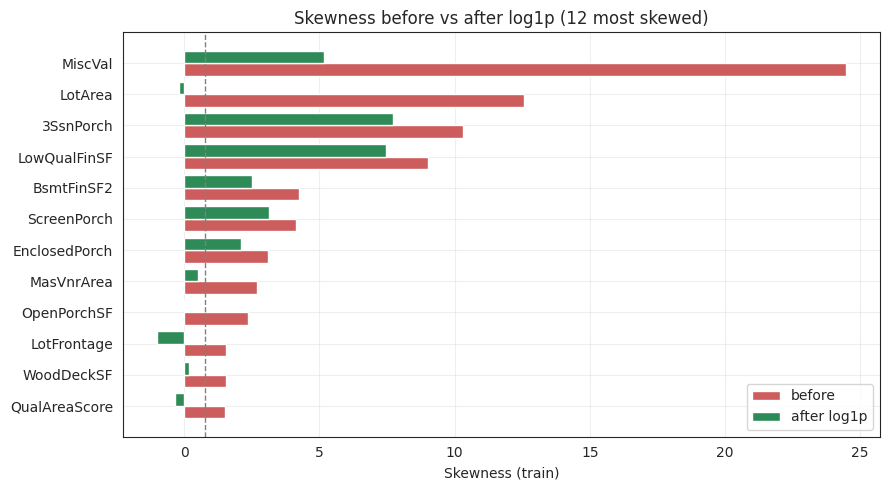

Saved ckpt_08_skew.pkl (3941 KB)


In [20]:
# ============================================================
# CELL 17: SKEWNESS CORRECTION
# Safe to re-run. Loads the Cell 16 checkpoint (always starts from unlogged data).
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_ONEHOT = f"{WORKING_DIR}/ckpt_07_onehot.pkl"
CKPT_SKEW   = f"{WORKING_DIR}/ckpt_08_skew.pkl"

if not os.path.exists(CKPT_ONEHOT):
    raise FileNotFoundError("ckpt_07_onehot.pkl missing. Re-run Cell 16 first.")
d = pd.read_pickle(CKPT_ONEHOT)
train_o, test_o = d["train"], d["test"]

feat_cols = [c for c in train_o.columns if c != "SalePrice"]
continuous = [c for c in feat_cols if train_o[c].nunique() > 10]     # skips binary / small-scale ordinals
skew_before = train_o[continuous].skew()

to_log = skew_before[skew_before > 0.75].index.tolist()
negative = skew_before[skew_before < -0.75].sort_values()

# log1p needs values >= 0 (checked on both train and test)
assert (train_o[to_log] >= 0).all().all() and (test_o[to_log] >= 0).all().all(), "Negative values would break log1p"

train_s, test_s = train_o.copy(), test_o.copy()
train_s[to_log] = np.log1p(train_s[to_log])
test_s[to_log]  = np.log1p(test_s[to_log])
skew_after = train_s[to_log].skew()

print("=" * 55)
print("SKEWNESS CORRECTION")
print("=" * 55)
print(f"Continuous features checked: {len(continuous)}")
print(f"log1p applied to           : {len(to_log)} features (skew > 0.75 on train)")
print(f"Mean skew of these features: {skew_before[to_log].mean():.2f} -> {skew_after.mean():.2f}")

table = pd.DataFrame({"before": skew_before[to_log], "after": skew_after}).sort_values("before", ascending=False)
print("\nTop 15 by original skew:")
print(table.head(15).round(2).to_string())

still = table[table["after"].abs() > 0.75]
print(f"\nStill |skew| > 0.75 after log1p ({len(still)}): {still.index.tolist()}")
print("-> These are mostly 'zero for most houses' columns (e.g. MiscVal, LowQualFinSF); log1p cannot fix a spike at zero.")
print(f"\nLeft-skewed (skew < -0.75), not transformed: {negative.round(2).to_dict()}")

# ---------- Verify ----------
assert np.isfinite(train_s[feat_cols].values).all() and np.isfinite(test_s[feat_cols].values).all(), "NaN/inf after log1p"
assert list(train_s.drop(columns=["SalePrice"]).columns) == list(test_s.columns), "Column mismatch"
assert len(train_s) == 1458 and len(test_s) == 1459, "Row count changed"
print("\nAll assertions passed.")

# ---------- Plot ----------
top = table.head(12).iloc[::-1]
pos = np.arange(len(top))
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(pos - 0.2, top["before"], height=0.4, color="indianred", label="before")
ax.barh(pos + 0.2, top["after"], height=0.4, color="seagreen", label="after log1p")
ax.set_yticks(pos); ax.set_yticklabels(top.index)
ax.axvline(0.75, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Skewness (train)"); ax.set_title("Skewness before vs after log1p (12 most skewed)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- Checkpoint ----------
pd.to_pickle({"train": train_s, "test": test_s, "train_ids": d["train_ids"], "test_ids": d["test_ids"],
              "log_cols": to_log, "new_feats": d["new_feats"]}, CKPT_SKEW)
print(f"Saved {os.path.basename(CKPT_SKEW)} ({os.path.getsize(CKPT_SKEW)/1024:.0f} KB)")

## Cell 18: Target Transformation
- Apply `log1p` to `SalePrice` and verify the result is close to normal (skewness, and share of values within 1 and 2 standard deviations)
- Build the final model-ready `X_train`, `y_log` and `X_test`, and save `ckpt_09_model_ready.pkl`

TARGET: BEFORE vs AFTER log1p
Skewness :  1.881 ->  0.122
Kurtosis :  6.523 ->  0.805
Share within 1 std: 71.3%  (normal: 68.3%)
Share within 2 std: 95.1%  (normal: 95.4%)

All assertions passed (expm1 reverses log1p exactly).


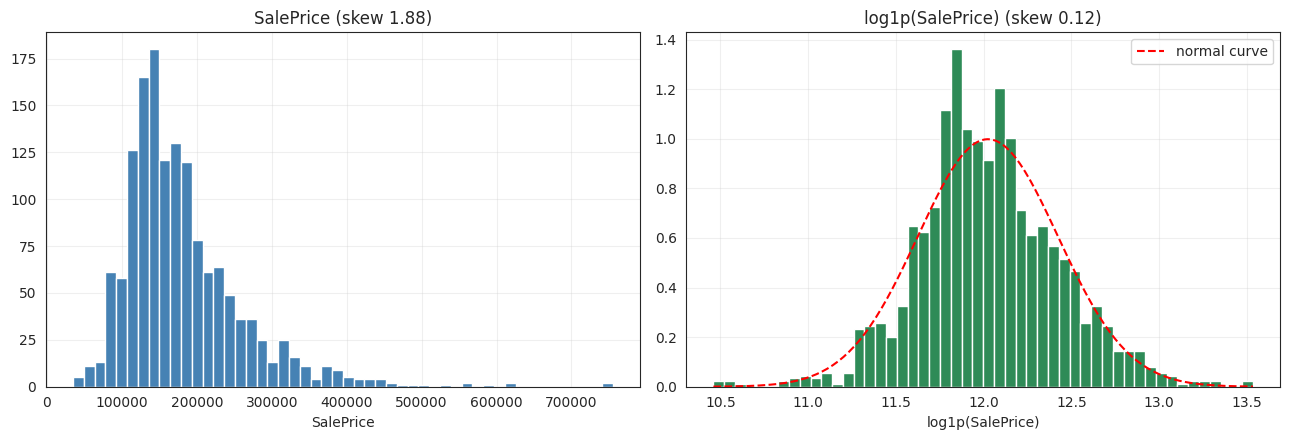

MODEL-READY DATA
X_train: (1458, 171) | y_log: (1458,) | X_test: (1459, 171)
Features: 171 | log-transformed features: 19

Saved ckpt_09_model_ready.pkl (3939 KB)


In [21]:
# ============================================================
# CELL 18: TARGET TRANSFORMATION
# Safe to re-run. Loads the Cell 17 checkpoint.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_SKEW  = f"{WORKING_DIR}/ckpt_08_skew.pkl"
CKPT_READY = f"{WORKING_DIR}/ckpt_09_model_ready.pkl"

if not os.path.exists(CKPT_SKEW):
    raise FileNotFoundError("ckpt_08_skew.pkl missing. Re-run Cell 17 first.")
d = pd.read_pickle(CKPT_SKEW)
train_s, test_s = d["train"], d["test"]

# ---------- Target transformation ----------
y_raw = train_s["SalePrice"].reset_index(drop=True)
y_log = np.log1p(y_raw)

X_train = train_s.drop(columns=["SalePrice"]).reset_index(drop=True)
X_test  = test_s.reset_index(drop=True)

# ---------- Near-normal check ----------
z = (y_log - y_log.mean()) / y_log.std()
print("=" * 55)
print("TARGET: BEFORE vs AFTER log1p")
print("=" * 55)
print(f"Skewness : {y_raw.skew():6.3f} -> {y_log.skew():6.3f}")
print(f"Kurtosis : {y_raw.kurt():6.3f} -> {y_log.kurt():6.3f}")
print(f"Share within 1 std: {(z.abs() <= 1).mean()*100:.1f}%  (normal: 68.3%)")
print(f"Share within 2 std: {(z.abs() <= 2).mean()*100:.1f}%  (normal: 95.4%)")

# ---------- Verify ----------
assert np.allclose(np.expm1(y_log), y_raw), "expm1 does not invert log1p"
assert np.isfinite(y_log).all(), "NaN/inf in target"
assert list(X_train.columns) == list(X_test.columns), "Column mismatch"
assert len(X_train) == len(y_log) == 1458 and len(X_test) == 1459, "Row count changed"
assert np.isfinite(X_train.values).all() and np.isfinite(X_test.values).all(), "NaN/inf in features"
print("\nAll assertions passed (expm1 reverses log1p exactly).")

# ---------- Plot ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(y_raw, bins=50, color="steelblue", edgecolor="white")
axes[0].set_title(f"SalePrice (skew {y_raw.skew():.2f})"); axes[0].set_xlabel("SalePrice")
axes[1].hist(y_log, bins=50, color="seagreen", edgecolor="white", density=True)
xs = np.linspace(y_log.min(), y_log.max(), 200)
axes[1].plot(xs, np.exp(-0.5 * ((xs - y_log.mean()) / y_log.std()) ** 2) / (y_log.std() * np.sqrt(2 * np.pi)),
             "r--", label="normal curve")
axes[1].set_title(f"log1p(SalePrice) (skew {y_log.skew():.2f})"); axes[1].set_xlabel("log1p(SalePrice)")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- Final summary & checkpoint ----------
print("=" * 55)
print("MODEL-READY DATA")
print("=" * 55)
print(f"X_train: {X_train.shape} | y_log: {y_log.shape} | X_test: {X_test.shape}")
print(f"Features: {X_train.shape[1]} | log-transformed features: {len(d['log_cols'])}")

pd.to_pickle({"X_train": X_train, "y_log": y_log, "X_test": X_test,
              "train_ids": d["train_ids"], "test_ids": d["test_ids"],
              "columns": X_train.columns.tolist()}, CKPT_READY)
print(f"\nSaved {os.path.basename(CKPT_READY)} ({os.path.getsize(CKPT_READY)/1024:.0f} KB)")

## Cell 19: Baseline, XGBoost Default
- Train XGBoost with **default** parameters using 5-fold CV and record the baseline RMSE (log scale)
- Also score a **no-engineering** version (imputed raw data, categoricals left to XGBoost) for the Cell 24 comparison
- Saves `ckpt_10_baseline.pkl`

In [22]:
# ============================================================
# CELL 19: BASELINE - XGBOOST DEFAULT, 5-FOLD CV
# Safe to re-run. Loads the Cell 18 (and Cell 11) checkpoints.
# ============================================================
import os
import time
import random
import warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_FOLDS = 5
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_READY = f"{WORKING_DIR}/ckpt_09_model_ready.pkl"
CKPT_CLEAN = f"{WORKING_DIR}/ckpt_02_clean.pkl"
CKPT_BASE  = f"{WORKING_DIR}/ckpt_10_baseline.pkl"

if not os.path.exists(CKPT_READY):
    raise FileNotFoundError("ckpt_09_model_ready.pkl missing. Re-run Cells 11-18 first.")
d = pd.read_pickle(CKPT_READY)
X, y = d["X_train"], d["y_log"]
print(f"X: {X.shape} | y: {y.shape}")

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

# Same folds will be reused in Cells 19-23
folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X))

def cv_default(X_cv, **extra):
    """5-fold CV of default XGBoost; returns OOF predictions and per-fold RMSE."""
    oof, scores = np.zeros(len(X_cv)), []
    for tr, va in folds:
        model = XGBRegressor(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE,
                             verbosity=0, **extra)
        model.fit(X_cv.iloc[tr], y.iloc[tr])
        oof[va] = model.predict(X_cv.iloc[va])
        scores.append(rmse(y.iloc[va], oof[va]))
    return oof, scores

# ---------- Baseline on the full engineered pipeline ----------
t0 = time.time()
oof_full, scores_full = cv_default(X)
cv_full = rmse(y, oof_full)
print("\n" + "=" * 55)
print("BASELINE: XGBOOST DEFAULT (full pipeline, 171 features)")
print("=" * 55)
print(f"CV RMSE (log scale): {cv_full:.5f}")
print(f"Fold RMSE: {[round(s, 4) for s in scores_full]} | mean±std: "
      f"{np.mean(scores_full):.4f} ± {np.std(scores_full):.4f} | {time.time() - t0:.1f}s")

# ---------- Reference: NO feature engineering ----------
cv_noeng, scores_noeng = None, None
if os.path.exists(CKPT_CLEAN):
    try:
        clean = pd.read_pickle(CKPT_CLEAN)["train"].reset_index(drop=True)
        assert len(clean) == len(y), "Row mismatch with model-ready data"
        assert np.allclose(np.log1p(clean["SalePrice"]).values, y.values), "Target mismatch"
        X_raw = clean.drop(columns=["Id", "SalePrice"]).copy()
        for c in X_raw.select_dtypes(exclude=[np.number]).columns:
            X_raw[c] = X_raw[c].astype("category")          # XGBoost handles categoricals natively
        t0 = time.time()
        oof_noeng, scores_noeng = cv_default(X_raw, enable_categorical=True)
        cv_noeng = rmse(y, oof_noeng)
        print("\n" + "=" * 55)
        print(f"REFERENCE: XGBOOST DEFAULT, NO ENGINEERING ({X_raw.shape[1]} raw features)")
        print("=" * 55)
        print(f"CV RMSE (log scale): {cv_noeng:.5f} | {time.time() - t0:.1f}s")
        print(f"Engineering gain: {cv_noeng - cv_full:+.5f} RMSE "
              f"({(cv_noeng - cv_full) / cv_noeng * 100:.1f}% lower)")
    except Exception as e:
        print(f"\n[SKIPPED] no-engineering reference failed: {type(e).__name__}: {e}")
else:
    print("\n[SKIPPED] ckpt_02_clean.pkl not found (re-run Cell 11 for the no-engineering reference).")

# ---------- Checkpoint ----------
pd.to_pickle({"cv_full_default": cv_full, "scores_full_default": scores_full,
              "cv_no_engineering": cv_noeng, "scores_no_engineering": scores_noeng,
              "random_state": RANDOM_STATE, "n_folds": N_FOLDS}, CKPT_BASE)
print(f"\nSaved {os.path.basename(CKPT_BASE)}")

X: (1458, 171) | y: (1458,)

BASELINE: XGBOOST DEFAULT (full pipeline, 171 features)
CV RMSE (log scale): 0.13033
Fold RMSE: [0.1427, 0.121, 0.1326, 0.1367, 0.1169] | mean±std: 0.1300 ± 0.0097 | 2.3s

REFERENCE: XGBOOST DEFAULT, NO ENGINEERING (79 raw features)
CV RMSE (log scale): 0.13901 | 2.1s
Engineering gain: +0.00868 RMSE (6.2% lower)

Saved ckpt_10_baseline.pkl


## Cell 20: XGBoost + Early Stopping
- `n_estimators=3000`, `learning_rate=0.05`, `early_stopping_rounds=50`, so each fold stops at its own best round
- Report the best round per fold and the recommended `n_estimators`
- CV is slightly optimistic because early stopping looks at the validation fold, so Cell 21 re-checks the final settings without it
- Saves `ckpt_11_earlystop.pkl`

Fold 1: best round  420 | RMSE 0.11809
Fold 2: best round  312 | RMSE 0.11116
Fold 3: best round  529 | RMSE 0.12027
Fold 4: best round  198 | RMSE 0.11953
Fold 5: best round  486 | RMSE 0.10347

EARLY STOPPING RESULT
Best rounds per fold : [420, 312, 529, 198, 486] (mean 389)
Recommended n_estimators (mean + 10%): 428
CV RMSE (early-stopped): 0.11468 | fold mean±std: 0.11450 ± 0.00639
Baseline (default XGBoost): 0.13033 -> improvement +0.01565 (12.0%)
Time: 5.8s


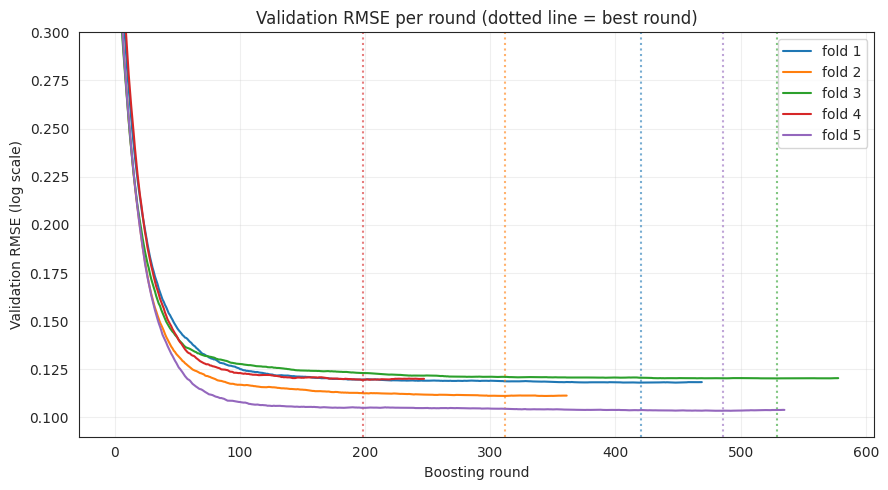

Saved ckpt_11_earlystop.pkl


In [23]:
# ============================================================
# CELL 20: XGBOOST + EARLY STOPPING
# Safe to re-run. Loads the Cell 18 and Cell 19 checkpoints.
# ============================================================
import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_FOLDS = 5
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_READY = f"{WORKING_DIR}/ckpt_09_model_ready.pkl"
CKPT_BASE  = f"{WORKING_DIR}/ckpt_10_baseline.pkl"
CKPT_ES    = f"{WORKING_DIR}/ckpt_11_earlystop.pkl"

if not os.path.exists(CKPT_READY):
    raise FileNotFoundError("ckpt_09_model_ready.pkl missing. Re-run Cells 11-18 first.")
d = pd.read_pickle(CKPT_READY)
X, y = d["X_train"], d["y_log"]
baseline = pd.read_pickle(CKPT_BASE)["cv_full_default"] if os.path.exists(CKPT_BASE) else None

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X))

params = dict(
    n_estimators=3000, learning_rate=0.05, max_depth=4, min_child_weight=3,
    subsample=0.8, colsample_bytree=0.6, reg_alpha=0.01, reg_lambda=1.0,
    early_stopping_rounds=50, eval_metric="rmse",
    tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, verbosity=0,
)

oof = np.zeros(len(X))
best_rounds, scores, curves = [], [], []
t0 = time.time()
for f, (tr, va) in enumerate(folds):
    model = XGBRegressor(**params)
    model.fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[va], y.iloc[va])], verbose=False)
    n_best = model.best_iteration + 1
    oof[va] = model.predict(X.iloc[va], iteration_range=(0, n_best))
    best_rounds.append(n_best)
    scores.append(rmse(y.iloc[va], oof[va]))
    curves.append(model.evals_result()["validation_0"]["rmse"])
    print(f"Fold {f + 1}: best round {n_best:>4} | RMSE {scores[-1]:.5f}")

cv_es = rmse(y, oof)
mean_round = float(np.mean(best_rounds))
recommended_n = int(round(mean_round * 1.1))     # +10% because the final model trains on 25% more data

print("\n" + "=" * 55)
print("EARLY STOPPING RESULT")
print("=" * 55)
print(f"Best rounds per fold : {best_rounds} (mean {mean_round:.0f})")
print(f"Recommended n_estimators (mean + 10%): {recommended_n}")
print(f"CV RMSE (early-stopped): {cv_es:.5f} | fold mean±std: {np.mean(scores):.5f} ± {np.std(scores):.5f}")
if baseline is not None:
    print(f"Baseline (default XGBoost): {baseline:.5f} -> improvement {baseline - cv_es:+.5f} "
          f"({(baseline - cv_es) / baseline * 100:.1f}%)")
print(f"Time: {time.time() - t0:.1f}s")

# ---------- Plot: validation curves ----------
fig, ax = plt.subplots(figsize=(9, 5))
for f, curve in enumerate(curves):
    ax.plot(curve, label=f"fold {f + 1}")
    ax.axvline(best_rounds[f], color=f"C{f}", linestyle=":", alpha=0.6)
ax.set_ylim(0.09, 0.30)
ax.set_xlabel("Boosting round"); ax.set_ylabel("Validation RMSE (log scale)")
ax.set_title("Validation RMSE per round (dotted line = best round)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- Checkpoint ----------
fixed = {k: v for k, v in params.items() if k not in ("early_stopping_rounds", "eval_metric")}
pd.to_pickle({"cv_early_stop": cv_es, "scores": scores, "best_rounds": best_rounds,
              "recommended_n_estimators": recommended_n, "params": fixed}, CKPT_ES)
print(f"Saved {os.path.basename(CKPT_ES)}")

## Cell 21: Optuna Hyperparameter Tuning
- 100 trials of TPE search, each scored by 5-fold CV with early stopping (it can take 10–20 minutes)
- Trials are stored in a SQLite file, so after a disconnect, re-running the cell **resumes** from the finished trials
- Plot the optimization history, verify the best settings with a fixed `n_estimators`, and save `ckpt_12_optuna.pkl`

Completed trials: 0 | remaining: 100
Search time this run: 422s

OPTUNA RESULT
Trials completed: 100 | best trial: #98
Best CV RMSE (early-stopped): 0.11346
Before tuning (Cell 20)     : 0.11468 -> improvement +0.00123
Best parameters:
  max_depth          3
  min_child_weight   3
  subsample          0.63562
  colsample_bytree   0.42289
  reg_alpha          0.00495
  reg_lambda         0.00925
  gamma              0.00660
Mean best round: 300 -> final n_estimators: 330

Verification CV RMSE (fixed n_estimators=330): 0.11356


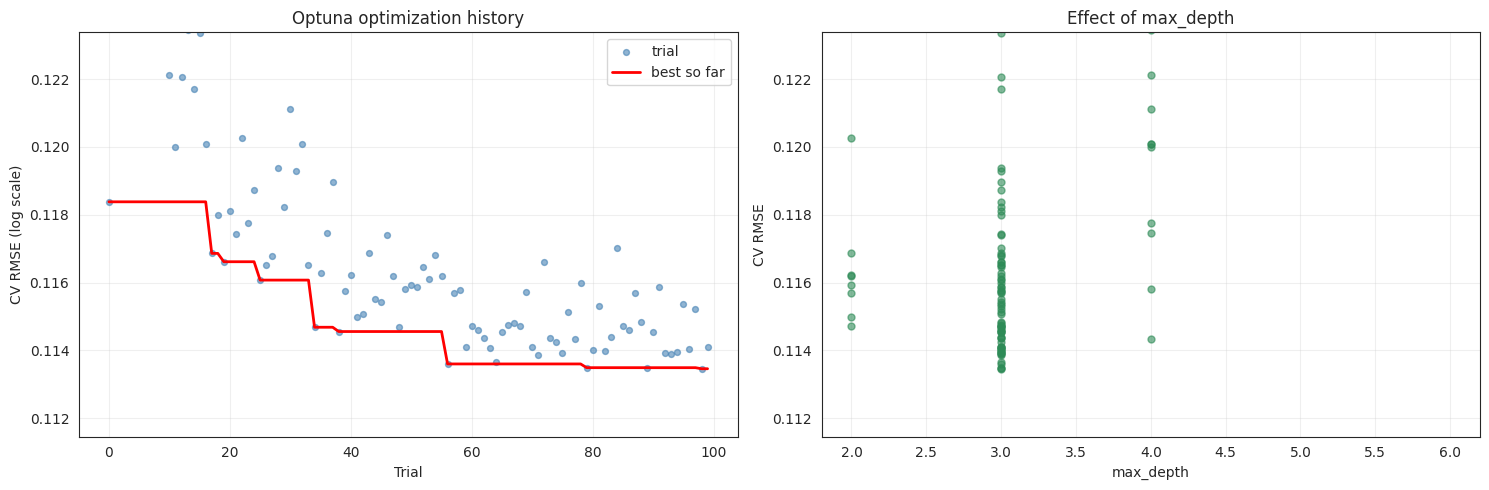


Saved ckpt_12_optuna.pkl (32 KB)


In [24]:
# ============================================================
# CELL 21: OPTUNA HYPERPARAMETER TUNING (100 TRIALS, RESUMABLE)
# Safe to re-run: finished trials are kept in a SQLite DB and are not repeated.
# ============================================================
import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.model_selection import KFold
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
N_FOLDS = 5
N_TRIALS = 100
RESET_STUDY = False        # set True to delete saved trials and start over
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_READY  = f"{WORKING_DIR}/ckpt_09_model_ready.pkl"
CKPT_ES     = f"{WORKING_DIR}/ckpt_11_earlystop.pkl"
CKPT_OPTUNA = f"{WORKING_DIR}/ckpt_12_optuna.pkl"
DB_PATH     = f"{WORKING_DIR}/optuna_xgb.db"

if not os.path.exists(CKPT_READY):
    raise FileNotFoundError("ckpt_09_model_ready.pkl missing. Re-run Cells 11-18 first.")
d = pd.read_pickle(CKPT_READY)
X, y = d["X_train"], d["y_log"]
es = pd.read_pickle(CKPT_ES) if os.path.exists(CKPT_ES) else None

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X))
LEARNING_RATE = 0.05

def objective(trial):
    params = dict(
        n_estimators=3000, learning_rate=LEARNING_RATE,
        max_depth=trial.suggest_int("max_depth", 2, 6),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        gamma=trial.suggest_float("gamma", 0.0, 0.5),
        early_stopping_rounds=50, eval_metric="rmse",
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, verbosity=0,
    )
    oof, rounds = np.zeros(len(X)), []
    for tr, va in folds:
        model = XGBRegressor(**params)
        model.fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[va], y.iloc[va])], verbose=False)
        n_best = model.best_iteration + 1
        oof[va] = model.predict(X.iloc[va], iteration_range=(0, n_best))
        rounds.append(n_best)
    trial.set_user_attr("mean_best_round", float(np.mean(rounds)))
    return rmse(y, oof)

# ---------- Study with resumable storage ----------
storage = f"sqlite:///{DB_PATH}"
if RESET_STUDY and os.path.exists(DB_PATH):
    os.remove(DB_PATH)
    print("Previous study deleted.")
try:
    study = optuna.create_study(study_name="xgb_house_prices", storage=storage, load_if_exists=True,
                                direction="minimize",
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
except Exception as e:
    print(f"[WARNING] SQLite storage failed ({type(e).__name__}); using in-memory study (no resume).")
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))

done = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
remaining = max(0, N_TRIALS - done)
print(f"Completed trials: {done} | remaining: {remaining}")

t0 = time.time()
if remaining > 0:
    study.optimize(objective, n_trials=remaining, show_progress_bar=False)
print(f"Search time this run: {time.time() - t0:.0f}s")

# ---------- Results ----------
best = study.best_trial
trials = study.trials_dataframe()
trials = trials[trials["state"] == "COMPLETE"].reset_index(drop=True)

print("\n" + "=" * 55)
print("OPTUNA RESULT")
print("=" * 55)
print(f"Trials completed: {len(trials)} | best trial: #{best.number}")
print(f"Best CV RMSE (early-stopped): {best.value:.5f}")
if es is not None:
    print(f"Before tuning (Cell 20)     : {es['cv_early_stop']:.5f} "
          f"-> improvement {es['cv_early_stop'] - best.value:+.5f}")
print("Best parameters:")
for k, v in best.params.items():
    print(f"  {k:<18} {v:.5f}" if isinstance(v, float) else f"  {k:<18} {v}")

best_n = int(round(best.user_attrs["mean_best_round"] * 1.1))
print(f"Mean best round: {best.user_attrs['mean_best_round']:.0f} -> final n_estimators: {best_n}")

# ---------- Verify with a fixed n_estimators (no early stopping on the validation fold) ----------
final_params = dict(n_estimators=best_n, learning_rate=LEARNING_RATE, tree_method="hist",
                    n_jobs=-1, random_state=RANDOM_STATE, verbosity=0, **best.params)
oof = np.zeros(len(X))
for tr, va in folds:
    oof[va] = XGBRegressor(**final_params).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va])
cv_verify = rmse(y, oof)
print(f"\nVerification CV RMSE (fixed n_estimators={best_n}): {cv_verify:.5f}")

# ---------- Optimization history ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(trials["number"], trials["value"], s=18, alpha=0.6, color="steelblue", label="trial")
axes[0].plot(trials["number"], trials["value"].cummin(), color="red", linewidth=2, label="best so far")
axes[0].set_ylim(trials["value"].min() - 0.002, np.percentile(trials["value"], 90))
axes[0].set_xlabel("Trial"); axes[0].set_ylabel("CV RMSE (log scale)")
axes[0].set_title("Optuna optimization history"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].scatter(trials["params_max_depth"], trials["value"], s=25, alpha=0.6, color="seagreen")
axes[1].set_ylim(trials["value"].min() - 0.002, np.percentile(trials["value"], 90))
axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("CV RMSE")
axes[1].set_title("Effect of max_depth"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- Checkpoint ----------
pd.to_pickle({"best_params": best.params, "final_params": final_params, "best_n_estimators": best_n,
              "best_cv_early_stop": best.value, "cv_verify_fixed_n": cv_verify,
              "n_trials": len(trials), "trials": trials}, CKPT_OPTUNA)
print(f"\nSaved {os.path.basename(CKPT_OPTUNA)} ({os.path.getsize(CKPT_OPTUNA)/1024:.0f} KB)")

## Cell 22: Base Models for Stacking
- Three diverse base models: tuned **XGBoost** (Cell 21 params), **Ridge** (scaled, alpha picked by CV) and **GradientBoosting** (sklearn, Huber loss)
- Each gets 5-fold out-of-fold predictions on train, and the averaged fold models predict test
- Result is a 3-column OOF matrix; saves `ckpt_13_oof.pkl`

In [25]:
# ============================================================
# CELL 22: BASE MODELS FOR STACKING (OOF PREDICTIONS)
# Safe to re-run. Loads the Cell 18 and Cell 21 checkpoints.
# ============================================================
import os
import time
import random
import warnings
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_FOLDS = 5
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_READY  = f"{WORKING_DIR}/ckpt_09_model_ready.pkl"
CKPT_OPTUNA = f"{WORKING_DIR}/ckpt_12_optuna.pkl"
CKPT_OOF    = f"{WORKING_DIR}/ckpt_13_oof.pkl"

for p in [CKPT_READY, CKPT_OPTUNA]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"{os.path.basename(p)} missing. Re-run Cells 11-21 first.")

d = pd.read_pickle(CKPT_READY)
X, y, X_test = d["X_train"], d["y_log"], d["X_test"]
opt = pd.read_pickle(CKPT_OPTUNA)
print(f"X: {X.shape} | X_test: {X_test.shape}")

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X))

def run_model(model, with_test=True):
    """OOF predictions on train; test predictions = average of the fold models."""
    oof, test_pred, scores = np.zeros(len(X)), np.zeros(len(X_test)), []
    for tr, va in folds:
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict(X.iloc[va])
        scores.append(rmse(y.iloc[va], oof[va]))
        if with_test:
            test_pred += m.predict(X_test) / N_FOLDS
    return oof, test_pred, scores

# ---------- Ridge: pick alpha by CV (cheap) ----------
print("=" * 55)
print("RIDGE ALPHA SEARCH (scaler fitted inside each fold)")
print("=" * 55)
ridge_scores = {}
for a in [3, 5, 8, 10, 15, 20, 30, 50]:
    oof_a, _, _ = run_model(make_pipeline(RobustScaler(), Ridge(alpha=a, random_state=RANDOM_STATE)),
                            with_test=False)
    ridge_scores[a] = rmse(y, oof_a)
    print(f"alpha {a:>3}: CV RMSE {ridge_scores[a]:.5f}")
best_alpha = min(ridge_scores, key=ridge_scores.get)
print(f"-> best alpha: {best_alpha}")

# ---------- Base models ----------
base_models = {
    "XGBoost": XGBRegressor(**opt["final_params"]),
    "Ridge": make_pipeline(RobustScaler(), Ridge(alpha=best_alpha, random_state=RANDOM_STATE)),
    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=1000, learning_rate=0.03, max_depth=3, max_features="sqrt",
        min_samples_leaf=10, min_samples_split=10, subsample=0.7, loss="huber",
        random_state=RANDOM_STATE),
}

names = list(base_models)
oof_mat, test_mat, fold_scores = {}, {}, {}
print("\n" + "=" * 55)
print("BASE MODELS: 5-FOLD OOF (RMSE on log1p(SalePrice))")
print("=" * 55)
for name, model in base_models.items():
    t0 = time.time()
    oof_mat[name], test_mat[name], fold_scores[name] = run_model(model)
    print(f"{name:<17} CV RMSE: {rmse(y, oof_mat[name]):.5f} | fold mean±std: "
          f"{np.mean(fold_scores[name]):.5f} ± {np.std(fold_scores[name]):.5f} | {time.time() - t0:5.1f}s")

P_oof  = np.column_stack([oof_mat[n] for n in names])
P_test = np.column_stack([test_mat[n] for n in names])

# ---------- Diversity: correlation of residuals (lower = more useful to blend) ----------
resid = pd.DataFrame({n: y.values - oof_mat[n] for n in names})
print("\nResidual correlation between base models:")
print(resid.corr().round(3).to_string())

# ---------- Verify ----------
assert P_oof.shape == (len(X), 3) and P_test.shape == (len(X_test), 3), "Unexpected matrix shape"
assert np.isfinite(P_oof).all() and np.isfinite(P_test).all(), "NaN/inf in predictions"
print(f"\nOOF matrix: {P_oof.shape} | test matrix: {P_test.shape}")

# ---------- Checkpoint ----------
pd.to_pickle({"names": names, "oof": P_oof, "test": P_test, "y": y.values,
              "base_cv": {n: rmse(y, oof_mat[n]) for n in names},
              "ridge_alpha": best_alpha}, CKPT_OOF)
print(f"Saved {os.path.basename(CKPT_OOF)} ({os.path.getsize(CKPT_OOF)/1024:.0f} KB)")

X: (1458, 171) | X_test: (1459, 171)
RIDGE ALPHA SEARCH (scaler fitted inside each fold)
alpha   3: CV RMSE 0.11519
alpha   5: CV RMSE 0.11500
alpha   8: CV RMSE 0.11487
alpha  10: CV RMSE 0.11482
alpha  15: CV RMSE 0.11476
alpha  20: CV RMSE 0.11475
alpha  30: CV RMSE 0.11480
alpha  50: CV RMSE 0.11507
-> best alpha: 20

BASE MODELS: 5-FOLD OOF (RMSE on log1p(SalePrice))
XGBoost           CV RMSE: 0.11356 | fold mean±std: 0.11341 ± 0.00583 |   2.9s
Ridge             CV RMSE: 0.11475 | fold mean±std: 0.11450 ± 0.00747 |   0.4s
GradientBoosting  CV RMSE: 0.11266 | fold mean±std: 0.11231 ± 0.00881 |  21.6s

Residual correlation between base models:
                  XGBoost  Ridge  GradientBoosting
XGBoost             1.000  0.845              0.92
Ridge               0.845  1.000              0.87
GradientBoosting    0.920  0.870              1.00

OOF matrix: (1458, 3) | test matrix: (1459, 3)
Saved ckpt_13_oof.pkl (80 KB)


## Cell 23: Meta-Learner Training
- Train a **Ridge meta-learner** (non-negative weights) on the 3-column OOF matrix
- Score it with CV on the OOF matrix (the meta-learner never sees the rows it predicts) and compare with the best base model and a simple average
- Fit on all OOF rows, predict test in log space, and save `ckpt_14_stack.pkl`

In [26]:
# ============================================================
# CELL 23: META-LEARNER TRAINING (RIDGE STACKING)
# Safe to re-run. Loads the Cell 22 checkpoint.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_FOLDS = 5
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
CKPT_OOF   = f"{WORKING_DIR}/ckpt_13_oof.pkl"
CKPT_STACK = f"{WORKING_DIR}/ckpt_14_stack.pkl"

if not os.path.exists(CKPT_OOF):
    raise FileNotFoundError("ckpt_13_oof.pkl missing. Re-run Cell 22 first.")
d = pd.read_pickle(CKPT_OOF)
names, P, P_test, y = d["names"], d["oof"], d["test"], d["y"]

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def make_meta(alpha):
    return Ridge(alpha=alpha, positive=True, solver="lbfgs", max_iter=50000, tol=1e-10)

folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(P))

# ---------- Meta-learner CV: fit on 4 folds of OOF, predict the 5th ----------
print("=" * 55)
print("META-LEARNER ALPHA SEARCH (CV on the OOF matrix)")
print("=" * 55)
meta_scores = {}
for a in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    pred = np.zeros(len(y))
    for tr, va in folds:
        pred[va] = make_meta(a).fit(P[tr], y[tr]).predict(P[va])
    meta_scores[a] = rmse(y, pred)
    print(f"alpha {a:<7}: stacking CV RMSE {meta_scores[a]:.5f}")
best_alpha = min(meta_scores, key=meta_scores.get)
stack_cv = meta_scores[best_alpha]

# ---------- Comparison ----------
base_cv = {n: rmse(y, P[:, i]) for i, n in enumerate(names)}
best_name = min(base_cv, key=base_cv.get)
avg_cv = rmse(y, P.mean(axis=1))

print("\n" + "=" * 55)
print("STACKING vs INDIVIDUAL MODELS (CV RMSE, log scale)")
print("=" * 55)
for n, v in sorted(base_cv.items(), key=lambda kv: kv[1]):
    print(f"{n:<17} {v:.5f}")
print(f"{'Simple average':<17} {avg_cv:.5f}")
print(f"{'Ridge stacking':<17} {stack_cv:.5f}  (alpha {best_alpha})")
print(f"\nBest individual: {best_name} {base_cv[best_name]:.5f} -> stacking improves by "
      f"{base_cv[best_name] - stack_cv:+.5f} ({(base_cv[best_name] - stack_cv) / base_cv[best_name] * 100:.1f}%)")

# ---------- Final meta-learner on all OOF rows ----------
meta = make_meta(best_alpha).fit(P, y)
coefs = dict(zip(names, meta.coef_.round(4)))
print("\n" + "=" * 55)
print("META-LEARNER")
print("=" * 55)
print(f"Coefficients: {coefs} | sum: {meta.coef_.sum():.3f} | intercept: {meta.intercept_:.4f}")

test_pred_log = meta.predict(P_test)
assert np.isfinite(test_pred_log).all() and len(test_pred_log) == 1459, "Bad test predictions"
print(f"Test predictions (log scale): min {test_pred_log.min():.3f} | mean {test_pred_log.mean():.3f} | "
      f"max {test_pred_log.max():.3f}")

# ---------- Checkpoint ----------
pd.to_pickle({"names": names, "meta_alpha": best_alpha, "coef": meta.coef_, "intercept": meta.intercept_,
              "stack_cv": stack_cv, "avg_cv": avg_cv, "base_cv": base_cv,
              "test_pred_log": test_pred_log}, CKPT_STACK)
print(f"\nSaved {os.path.basename(CKPT_STACK)}")

META-LEARNER ALPHA SEARCH (CV on the OOF matrix)
alpha 0.0001 : stacking CV RMSE 0.10961
alpha 0.001  : stacking CV RMSE 0.10961
alpha 0.01   : stacking CV RMSE 0.10961
alpha 0.1    : stacking CV RMSE 0.10957
alpha 1.0    : stacking CV RMSE 0.10936

STACKING vs INDIVIDUAL MODELS (CV RMSE, log scale)
GradientBoosting  0.11266
XGBoost           0.11356
Ridge             0.11475
Simple average    0.10892
Ridge stacking    0.10936  (alpha 1.0)

Best individual: GradientBoosting 0.11266 -> stacking improves by +0.00330 (2.9%)

META-LEARNER
Coefficients: {'XGBoost': np.float64(0.3273), 'Ridge': np.float64(0.3527), 'GradientBoosting': np.float64(0.3332)} | sum: 1.013 | intercept: -0.1594
Test predictions (log scale): min 10.711 | mean 12.010 | max 13.486

Saved ckpt_14_stack.pkl


## Cell 24: Final Model Comparison
Table of CV RMSE (log scale) for each stage: XGBoost without engineering → full pipeline (default) → early stopping → Optuna-tuned → stacking, showing what each stage contributed. Saves `ckpt_15_comparison.pkl`.

FINAL MODEL COMPARISON (5-fold CV RMSE on log1p(SalePrice), lower is better)
                              model  cv_rmse                            stage  delta_vs_prev  delta_vs_default
  XGBoost (no engineering, default)  0.13901             raw imputed features            NaN           0.00868
   XGBoost (full pipeline, default)  0.13033 + feature engineering & encoding       -0.00868           0.00000
XGBoost (full pipeline, early stop)  0.11468        + lr 0.05, early stopping       -0.01565          -0.01565
             XGBoost (Optuna-tuned)  0.11356               + 100-trial tuning       -0.00113          -0.01677
       Stacking (XGB + Ridge + GBR)  0.10936             + Ridge meta-learner       -0.00420          -0.02097

Best: Stacking (XGB + Ridge + GBR) with CV RMSE 0.10936
Total improvement over the no-engineering baseline: 0.02965 (21.3%)
Feature engineering + encoding alone: +0.00868
Tuning (early stop -> Optuna): +0.00113
Stacking (Optuna -> stack)   : +0.00420


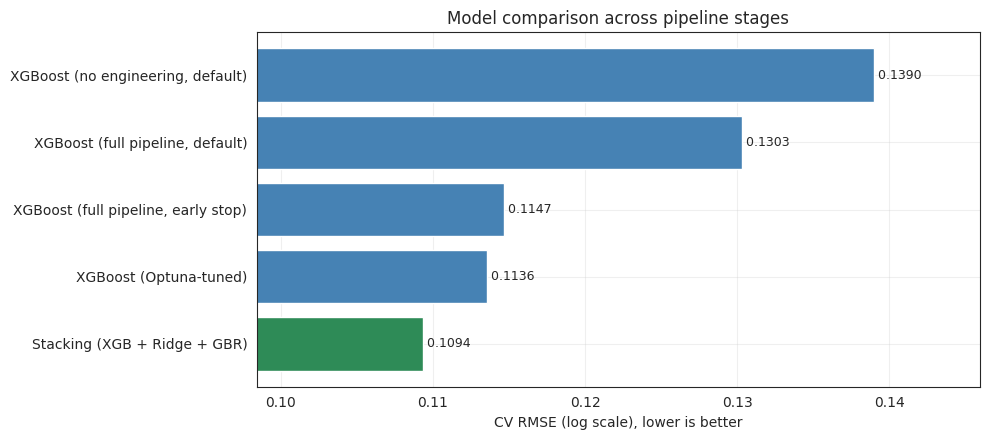

Saved ckpt_15_comparison.pkl


In [27]:
# ============================================================
# CELL 24: FINAL MODEL COMPARISON
# Safe to re-run. Loads checkpoints from Cells 19-23.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
paths = {
    "baseline": f"{WORKING_DIR}/ckpt_10_baseline.pkl",
    "earlystop": f"{WORKING_DIR}/ckpt_11_earlystop.pkl",
    "optuna": f"{WORKING_DIR}/ckpt_12_optuna.pkl",
    "stack": f"{WORKING_DIR}/ckpt_14_stack.pkl",
}
for k, p in paths.items():
    if not os.path.exists(p):
        raise FileNotFoundError(f"{os.path.basename(p)} missing. Re-run the earlier cells first.")
base, es, opt, stack = (pd.read_pickle(paths[k]) for k in ["baseline", "earlystop", "optuna", "stack"])

rows = [
    ("XGBoost (no engineering, default)",  base["cv_no_engineering"],      "raw imputed features"),
    ("XGBoost (full pipeline, default)",   base["cv_full_default"],        "+ feature engineering & encoding"),
    ("XGBoost (full pipeline, early stop)", es["cv_early_stop"],           "+ lr 0.05, early stopping"),
    ("XGBoost (Optuna-tuned)",             opt["cv_verify_fixed_n"],       "+ 100-trial tuning"),
    ("Stacking (XGB + Ridge + GBR)",       stack["stack_cv"],              "+ Ridge meta-learner"),
]
table = pd.DataFrame(rows, columns=["model", "cv_rmse", "stage"])
table["delta_vs_prev"] = table["cv_rmse"].diff()
table["delta_vs_default"] = table["cv_rmse"] - base["cv_full_default"]

print("=" * 70)
print("FINAL MODEL COMPARISON (5-fold CV RMSE on log1p(SalePrice), lower is better)")
print("=" * 70)
print(table.round(5).to_string(index=False))

if table["cv_rmse"].isna().any():
    print("\n[Note] A missing value means that stage was skipped earlier (e.g. no-engineering reference in Cell 19).")

valid = table.dropna(subset=["cv_rmse"])
best = valid.loc[valid["cv_rmse"].idxmin()]
print(f"\nBest: {best['model']} with CV RMSE {best['cv_rmse']:.5f}")
if pd.notna(base["cv_no_engineering"]):
    gain = base["cv_no_engineering"] - best["cv_rmse"]
    print(f"Total improvement over the no-engineering baseline: {gain:.5f} "
          f"({gain / base['cv_no_engineering'] * 100:.1f}%)")
fe_gain = (base["cv_no_engineering"] - base["cv_full_default"]) if pd.notna(base["cv_no_engineering"]) else None
if fe_gain is not None:
    print(f"Feature engineering + encoding alone: {fe_gain:+.5f}")
print(f"Tuning (early stop -> Optuna): {es['cv_early_stop'] - opt['cv_verify_fixed_n']:+.5f}")
print(f"Stacking (Optuna -> stack)   : {opt['cv_verify_fixed_n'] - stack['stack_cv']:+.5f}")

# ---------- Plot ----------
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_df = valid.iloc[::-1]
colors = ["seagreen" if m == best["model"] else "steelblue" for m in plot_df["model"]]
ax.barh(plot_df["model"], plot_df["cv_rmse"], color=colors)
for y_pos, v in enumerate(plot_df["cv_rmse"]):
    ax.text(v, y_pos, f" {v:.4f}", va="center", fontsize=9)
ax.set_xlim(plot_df["cv_rmse"].min() * 0.9, plot_df["cv_rmse"].max() * 1.05)
ax.set_xlabel("CV RMSE (log scale), lower is better")
ax.set_title("Model comparison across pipeline stages")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- Checkpoint ----------
pd.to_pickle(table, f"{WORKING_DIR}/ckpt_15_comparison.pkl")
print("Saved ckpt_15_comparison.pkl")

## Cell 25: SHAP Analysis
- Fit the tuned XGBoost on all rows and explain it with `shap.TreeExplainer`
- Beeswarm summary, waterfalls for the most and least expensive house, and dependence plots for `OverallQual` and `GrLivArea`
- Quantify 3 insights in plain language and save the figures to `/kaggle/working/images/`

In-sample RMSE (log): 0.06938  (explanation model, not a CV score)
Method: shap.TreeExplainer | additivity check: max |base + sum(SHAP) - prediction| = 1.24e-05

TOP 15 FEATURES BY MEAN |SHAP| (log-price units)
QualAreaScore      0.0908
TotalSF            0.0582
Neighborhood_TE    0.0375
OverallQual        0.0316
TotalBaths         0.0197
OverallScore       0.0187
BsmtFinSF1         0.0155
KitchenQual        0.0141
LotArea            0.0135
GarageCars         0.0134
AgeRemod           0.0134
ExterQual          0.0117
OverallCond        0.0110
TotalPorchSF       0.0109
GarageFinish       0.0100


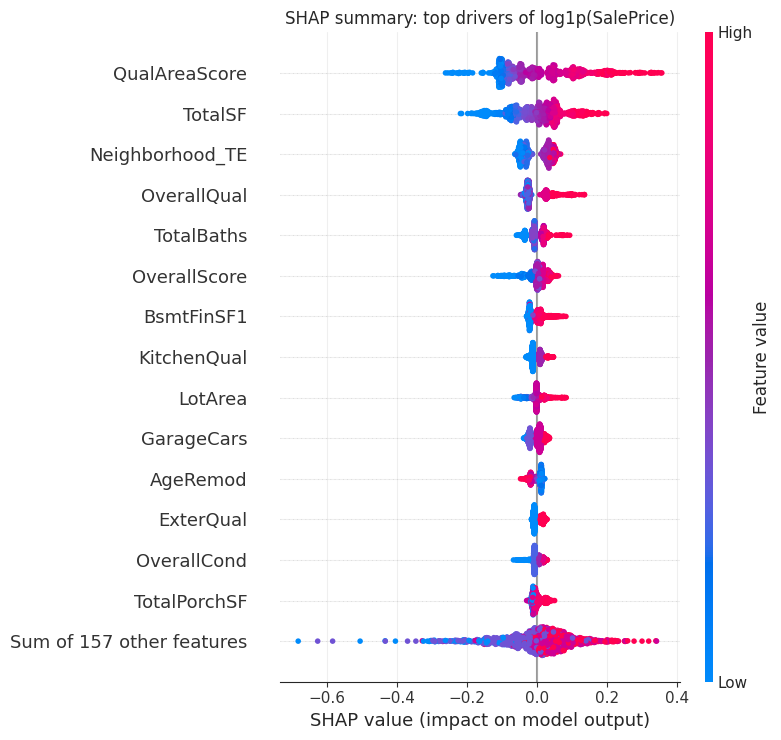


WATERFALLS (explain one house at a time)


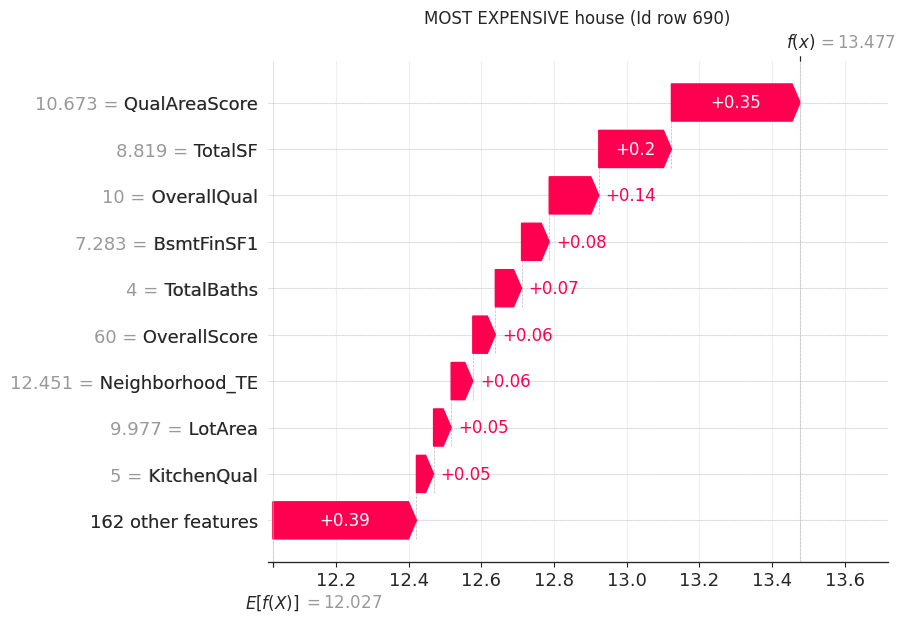

MOST EXPENSIVE house: actual $755,000 | predicted $712,862
   QualAreaScore      value=    10.67  SHAP=+0.354
   TotalSF            value=     8.82  SHAP=+0.200
   OverallQual        value=    10.00  SHAP=+0.136
   BsmtFinSF1         value=     7.28  SHAP=+0.076
   TotalBaths         value=     4.00  SHAP=+0.072


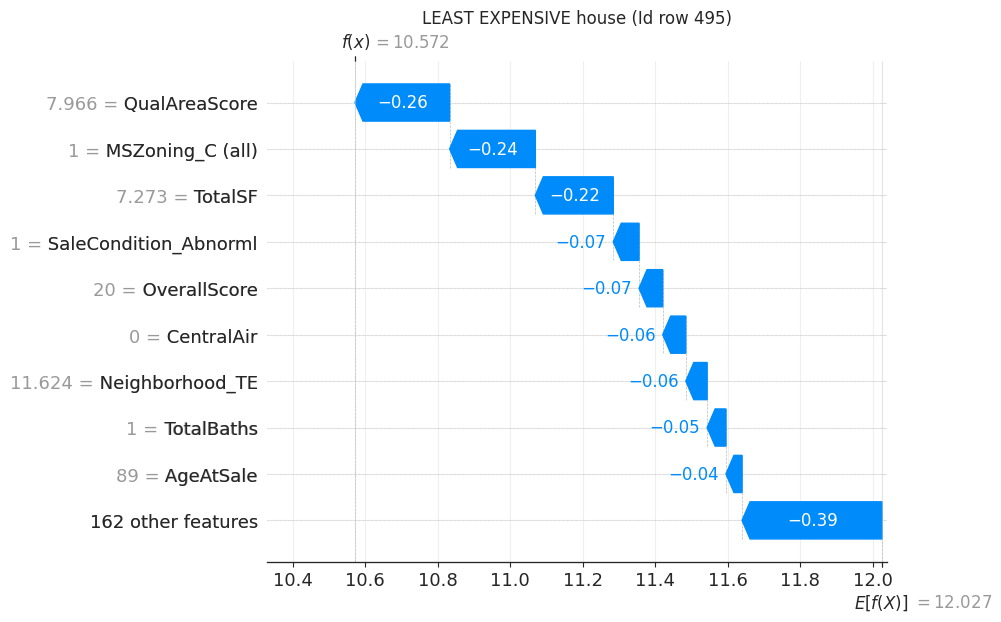

LEAST EXPENSIVE house: actual $34,900 | predicted $39,009
   QualAreaScore      value=     7.97  SHAP=-0.261
   MSZoning_C (all)   value=     1.00  SHAP=-0.237
   TotalSF            value=     7.27  SHAP=-0.215
   SaleCondition_Abnorml value=     1.00  SHAP=-0.071
   OverallScore       value=    20.00  SHAP=-0.065


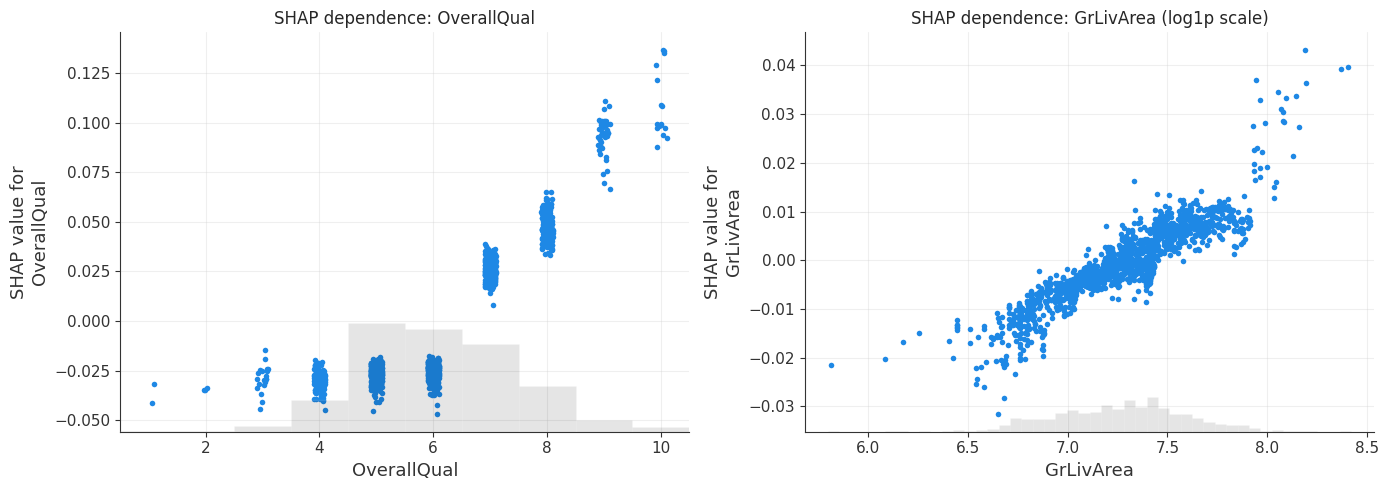


QUANTIFIED SHAP INSIGHTS (for the README)
1. OverallQual 9 vs 7: +7.0% (about $+11,377 at the median price of $163,000), all else equal.
2. GrLivArea, top vs bottom quartile (median 2,076 vs 954): +1.9% (about $+3,106).
3. Neighborhood_TE, top vs bottom quartile: +9.2% (about $+14,943).
4. AgeAtSale, top vs bottom quartile (median 79 vs 2): -2.1% (about $-3,478).

Figures saved in /kaggle/working/images: ['actual_vs_predicted.png', 'correlation_heatmap.png', 'grlivarea_outliers.png', 'missing_values.png', 'model_comparison.png', 'optuna_history.png', 'residuals.png', 'saleprice_distribution.png', 'shap_dependence.png', 'shap_summary.png', 'shap_waterfall_cheap.png', 'shap_waterfall_expensive.png']
Saved ckpt_16_shap.pkl


In [33]:
# ============================================================
# CELL 25: SHAP ANALYSIS (TUNED XGBOOST)
# Safe to re-run. Loads the Cell 18, 17 and 21 checkpoints.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
IMG_DIR = f"{WORKING_DIR}/images"
os.makedirs(IMG_DIR, exist_ok=True)
CKPT_READY  = f"{WORKING_DIR}/ckpt_09_model_ready.pkl"
CKPT_SKEW   = f"{WORKING_DIR}/ckpt_08_skew.pkl"
CKPT_OPTUNA = f"{WORKING_DIR}/ckpt_12_optuna.pkl"
CKPT_SHAP   = f"{WORKING_DIR}/ckpt_16_shap.pkl"

for p in [CKPT_READY, CKPT_SKEW, CKPT_OPTUNA]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"{os.path.basename(p)} missing. Re-run Cells 11-21 first.")

d = pd.read_pickle(CKPT_READY)
X, y = d["X_train"], d["y_log"]
log_cols = set(pd.read_pickle(CKPT_SKEW)["log_cols"])
opt = pd.read_pickle(CKPT_OPTUNA)

# ---------- Fit tuned XGBoost on all training rows ----------
model = XGBRegressor(**opt["final_params"]).fit(X, y)
pred_log = model.predict(X)
print(f"In-sample RMSE (log): {np.sqrt(np.mean((y - pred_log) ** 2)):.5f}  (explanation model, not a CV score)")

# ---------- SHAP values ----------
try:
    sv = shap.TreeExplainer(model)(X)
    method = "shap.TreeExplainer"
except Exception as e:
    print(f"[Fallback] TreeExplainer failed ({type(e).__name__}); using XGBoost's built-in SHAP values.")
    contrib = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
    sv = shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1],
                          data=X.values, feature_names=X.columns.tolist())
    method = "XGBoost pred_contribs"

recon = np.asarray(sv.base_values) + sv.values.sum(axis=1)
max_gap = float(np.abs(recon - pred_log).max())
assert max_gap < 1e-2, f"SHAP values do not add up to predictions (gap {max_gap})"
print(f"Method: {method} | additivity check: max |base + sum(SHAP) - prediction| = {max_gap:.2e}")

shap_df = pd.DataFrame(sv.values, columns=X.columns)
mean_abs = shap_df.abs().mean().sort_values(ascending=False)

print("\n" + "=" * 55)
print("TOP 15 FEATURES BY MEAN |SHAP| (log-price units)")
print("=" * 55)
print(mean_abs.head(15).round(4).to_string())

# ---------- Beeswarm ----------
plt.figure(figsize=(10, 8))
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP summary: top drivers of log1p(SalePrice)")
plt.tight_layout()
plt.gcf().savefig(f"{IMG_DIR}/shap_summary.png", dpi=130, bbox_inches="tight")
plt.show()

# ---------- Waterfalls: most & least expensive house ----------
def explain_house(pos, label, fname):
    plt.figure(figsize=(9, 6))
    shap.plots.waterfall(sv[pos], max_display=10, show=False)
    plt.title(f"{label} (Id row {pos})")
    plt.gcf().savefig(f"{IMG_DIR}/{fname}", dpi=130, bbox_inches="tight")
    plt.show()
    top = shap_df.iloc[pos].reindex(shap_df.iloc[pos].abs().sort_values(ascending=False).index).head(5)
    print(f"{label}: actual ${np.expm1(y.iloc[pos]):,.0f} | predicted ${np.expm1(pred_log[pos]):,.0f}")
    for feat, val in top.items():
        print(f"   {feat:<18} value={X.iloc[pos][feat]:>9.2f}  SHAP={val:+.3f}")

print("\n" + "=" * 55)
print("WATERFALLS (explain one house at a time)")
print("=" * 55)
explain_house(int(y.idxmax()), "MOST EXPENSIVE house", "shap_waterfall_expensive.png")
explain_house(int(y.idxmin()), "LEAST EXPENSIVE house", "shap_waterfall_cheap.png")

# ---------- Dependence plots ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
shap.plots.scatter(sv[:, "OverallQual"], ax=axes[0], show=False)
axes[0].set_title("SHAP dependence: OverallQual")
shap.plots.scatter(sv[:, "GrLivArea"], ax=axes[1], show=False)
axes[1].set_title("SHAP dependence: GrLivArea (log1p scale)")
plt.tight_layout()
fig.savefig(f"{IMG_DIR}/shap_dependence.png", dpi=130, bbox_inches="tight")
plt.show()

# ---------- Quantified insights in plain language ----------
med_price = float(np.expm1(y).median())
insights = []

def pct_dollars(diff):
    return float(np.expm1(diff) * 100), float(med_price * np.expm1(diff))

oq = shap_df["OverallQual"].groupby(X["OverallQual"].values).mean()
if 9 in oq.index and 7 in oq.index:
    pct, usd = pct_dollars(oq[9] - oq[7])
    insights.append(f"OverallQual 9 vs 7: {pct:+.1f}% (about ${usd:+,.0f} at the median price of ${med_price:,.0f}), all else equal.")

def band_effect(col, show_values=True):
    if col not in X.columns:
        return None
    q = pd.qcut(X[col].rank(method="first"), 4, labels=False)
    eff = shap_df[col].groupby(q).mean()
    pct, usd = pct_dollars(eff.iloc[3] - eff.iloc[0])
    lo, hi = X.loc[q == 0, col].median(), X.loc[q == 3, col].median()
    if col in log_cols:
        lo, hi = np.expm1(lo), np.expm1(hi)
    where = f" (median {hi:,.0f} vs {lo:,.0f})" if show_values else ""
    return f"{col}, top vs bottom quartile{where}: {pct:+.1f}% (about ${usd:+,.0f})."

for col, show in [("GrLivArea", True), ("Neighborhood_TE", False), ("AgeAtSale", True)]:
    line = band_effect(col, show)
    if line:
        insights.append(line)

print("\n" + "=" * 55)
print("QUANTIFIED SHAP INSIGHTS (for the README)")
print("=" * 55)
for i, line in enumerate(insights, 1):
    print(f"{i}. {line}")

print(f"\nFigures saved in {IMG_DIR}: {sorted(os.listdir(IMG_DIR))}")
pd.to_pickle({"mean_abs_shap": mean_abs, "insights": insights, "median_price": med_price}, CKPT_SHAP)
print("Saved ckpt_16_shap.pkl")

## Cell 26: Residual Analysis
- Use the **out-of-fold stacking predictions** (each house predicted by models that never saw it)
- Plots: actual vs predicted, residuals vs predicted, residuals vs `OverallQual`
- Text checks for systematic patterns by price band, quality level, predicted level and sale condition, plus the worst errors

Stacking CV RMSE: 0.10936 (Cell 23 reported 0.10936)

OVERALL ERROR
RMSE (log)            : 0.10936
MAE (dollars)         : $13,385
Median |% error|      : 5.44%
Within 10% of actual  : 75.4% of houses
R² (log scale)        : 0.9251
Mean residual         : -0.0000 (should be about 0)


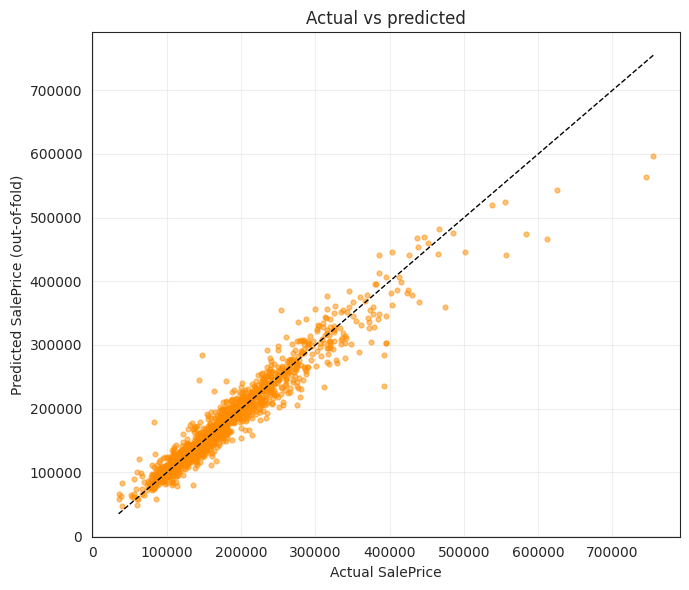

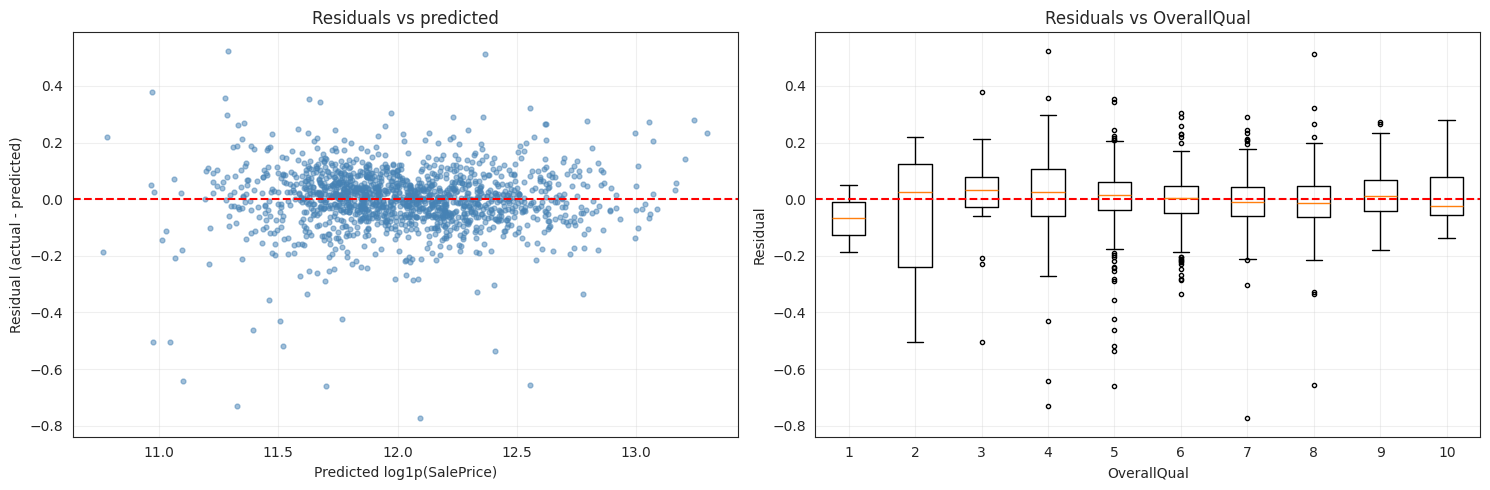


PATTERN 1: BY ACTUAL PRICE QUINTILE
             mean_resid    rmse
Q1 cheapest     -0.0414  0.1560
Q2               0.0047  0.1009
Q3               0.0111  0.0862
Q4              -0.0024  0.0778
Q5 priciest      0.0288  0.1078

PATTERN 2: BY OverallQual
      n  mean_resid    rmse
1     2     -0.0675  0.1364
2     3     -0.0863  0.3179
3    20      0.0132  0.1750
4   116      0.0128  0.1661
5   397      0.0049  0.1081
6   374     -0.0016  0.0867
7   319     -0.0086  0.0945
8   168     -0.0083  0.1149
9    43      0.0205  0.1063
10   16      0.0309  0.1326

PATTERN 3: SPREAD BY PREDICTED LEVEL (is variance constant?)
low     0.1304
mid     0.0895
high    0.1045

PATTERN 4: BY SALE CONDITION (mean residual when flag = 1)
SaleCondition_Abnorml      n= 101 | mean residual -0.0220 | rmse 0.1883
SaleCondition_Alloca       n=  12 | mean residual -0.0212 | rmse 0.2095
SaleCondition_Family       n=  20 | mean residual -0.0156 | rmse 0.2250
SaleCondition_Normal       n=1198 | mean residual +0.

In [34]:
# ============================================================
# CELL 26: RESIDUAL ANALYSIS (OUT-OF-FOLD STACKING PREDICTIONS)
# Safe to re-run. Loads the Cell 18, 22 and 23 checkpoints.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_FOLDS = 5
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
IMG_DIR = f"{WORKING_DIR}/images"
os.makedirs(IMG_DIR, exist_ok=True)
CKPT_READY = f"{WORKING_DIR}/ckpt_09_model_ready.pkl"
CKPT_OOF   = f"{WORKING_DIR}/ckpt_13_oof.pkl"
CKPT_STACK = f"{WORKING_DIR}/ckpt_14_stack.pkl"

for p in [CKPT_READY, CKPT_OOF, CKPT_STACK]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"{os.path.basename(p)} missing. Re-run Cells 11-23 first.")

ready = pd.read_pickle(CKPT_READY)
X, y_s, ids = ready["X_train"], ready["y_log"], ready["train_ids"]
oofd, stack = pd.read_pickle(CKPT_OOF), pd.read_pickle(CKPT_STACK)
P, y = oofd["oof"], oofd["y"]
assert np.allclose(y, y_s.values), "Target mismatch between checkpoints"

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

# ---------- Stacking OOF predictions (same recipe as Cell 23) ----------
folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(P))
pred_log = np.zeros(len(y))
for tr, va in folds:
    meta = Ridge(alpha=stack["meta_alpha"], positive=True, solver="lbfgs", max_iter=50000, tol=1e-10)
    pred_log[va] = meta.fit(P[tr], y[tr]).predict(P[va])
print(f"Stacking CV RMSE: {rmse(y, pred_log):.5f} (Cell 23 reported {stack['stack_cv']:.5f})")

resid = y - pred_log                      # positive = model UNDER-predicted the price
actual, predicted = np.expm1(y), np.expm1(pred_log)
pct_err = (predicted - actual) / actual * 100

print("\n" + "=" * 55)
print("OVERALL ERROR")
print("=" * 55)
print(f"RMSE (log)            : {rmse(y, pred_log):.5f}")
print(f"MAE (dollars)         : ${np.mean(np.abs(predicted - actual)):,.0f}")
print(f"Median |% error|      : {np.median(np.abs(pct_err)):.2f}%")
print(f"Within 10% of actual  : {(np.abs(pct_err) <= 10).mean() * 100:.1f}% of houses")
print(f"R² (log scale)        : {1 - np.sum(resid ** 2) / np.sum((y - y.mean()) ** 2):.4f}")
print(f"Mean residual         : {resid.mean():+.4f} (should be about 0)")

# ---------- Figure 1: actual vs predicted ----------
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(actual, predicted, s=12, alpha=0.5, color="darkorange")
lim = [actual.min(), actual.max()]
ax.plot(lim, lim, "k--", linewidth=1)
ax.set_xlabel("Actual SalePrice"); ax.set_ylabel("Predicted SalePrice (out-of-fold)")
ax.set_title("Actual vs predicted"); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(f"{IMG_DIR}/actual_vs_predicted.png", dpi=130, bbox_inches="tight")
plt.show()

# ---------- Figure 2: residual diagnostics ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(pred_log, resid, s=12, alpha=0.5, color="steelblue")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted log1p(SalePrice)"); axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs predicted"); axes[0].grid(alpha=0.3)

levels = sorted(X["OverallQual"].unique())
axes[1].boxplot([resid[X["OverallQual"].values == q] for q in levels], labels=[int(q) for q in levels],
                showfliers=True, flierprops=dict(markersize=3))
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("OverallQual"); axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs OverallQual"); axes[1].grid(alpha=0.3)
plt.tight_layout()
fig.savefig(f"{IMG_DIR}/residuals.png", dpi=130, bbox_inches="tight")
plt.show()

# ---------- Systematic patterns (positive mean residual = under-prediction) ----------
print("\n" + "=" * 55)
print("PATTERN 1: BY ACTUAL PRICE QUINTILE")
print("=" * 55)
band = pd.qcut(pd.Series(actual), 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 priciest"])
print(pd.DataFrame({"mean_resid": pd.Series(resid).groupby(band).mean(),
                    "rmse": pd.Series(resid).groupby(band).apply(lambda r: np.sqrt((r ** 2).mean()))}).round(4).to_string())

print("\n" + "=" * 55)
print("PATTERN 2: BY OverallQual")
print("=" * 55)
by_q = pd.DataFrame({"n": pd.Series(resid).groupby(X["OverallQual"].values).size(),
                     "mean_resid": pd.Series(resid).groupby(X["OverallQual"].values).mean(),
                     "rmse": pd.Series(resid).groupby(X["OverallQual"].values).apply(lambda r: np.sqrt((r ** 2).mean()))})
print(by_q.round(4).to_string())

print("\n" + "=" * 55)
print("PATTERN 3: SPREAD BY PREDICTED LEVEL (is variance constant?)")
print("=" * 55)
tier = pd.qcut(pd.Series(pred_log), 3, labels=["low", "mid", "high"])
print(pd.Series(resid).groupby(tier).std().round(4).to_string())

sale_flags = [c for c in X.columns if c.startswith("SaleCondition_")]
if sale_flags:
    print("\n" + "=" * 55)
    print("PATTERN 4: BY SALE CONDITION (mean residual when flag = 1)")
    print("=" * 55)
    for c in sale_flags:
        m = X[c].values == 1
        print(f"{c:<26} n={int(m.sum()):>4} | mean residual {resid[m].mean():+.4f} | rmse {np.sqrt((resid[m] ** 2).mean()):.4f}")

# ---------- Worst errors ----------
worst = pd.DataFrame({"Id": ids.values, "actual": actual.round(0), "predicted": predicted.round(0),
                      "resid_log": resid.round(3), "pct_error": pct_err.round(1),
                      "OverallQual": X["OverallQual"].values})
worst = worst.reindex(np.argsort(-np.abs(resid))).head(8)
print("\n" + "=" * 55)
print("8 WORST PREDICTIONS")
print("=" * 55)
print(worst.to_string(index=False))
share = np.sort(resid ** 2)[::-1][:15].sum() / (resid ** 2).sum() * 100
print(f"\nThe 15 worst houses account for {share:.1f}% of total squared error.")

## Cell 27: Generate Submission
- Test features were already processed by the same pipeline as train (train-only statistics) in Cells 11–18
- Use the stacking predictions from Cell 23, convert back with `expm1`, check shape, ids and value range, and write `/kaggle/working/submission.csv`

In [30]:
# ============================================================
# CELL 27: GENERATE SUBMISSION (STACKING)
# Safe to re-run. Loads the Cell 18 and Cell 23 checkpoints.
# ============================================================
import os
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
WORKING_DIR = "/kaggle/working"
SUBMISSION_PATH = f"{WORKING_DIR}/submission.csv"
CKPT_READY = f"{WORKING_DIR}/ckpt_09_model_ready.pkl"
CKPT_STACK = f"{WORKING_DIR}/ckpt_14_stack.pkl"

for p in [CKPT_READY, CKPT_STACK]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"{os.path.basename(p)} missing. Re-run Cells 11-23 first.")

CANDIDATE_DIRS = [
    "/kaggle/input/house-prices-advanced-regression-techniques",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
]
INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/sample_submission.csv")), None)
if INPUT_DIR is None:
    raise FileNotFoundError("Competition data not found. Re-run Cell 2.")
sample_sub = pd.read_csv(f"{INPUT_DIR}/sample_submission.csv")

ready = pd.read_pickle(CKPT_READY)
stack = pd.read_pickle(CKPT_STACK)
X_train, X_test, y_log = ready["X_train"], ready["X_test"], ready["y_log"]
test_ids = ready["test_ids"].reset_index(drop=True)

# ---------- Pipeline consistency (test went through the same steps as train) ----------
assert list(X_train.columns) == list(X_test.columns), "Train/test feature columns differ"
assert np.isfinite(X_test.values).all(), "NaN/inf in test features"
print(f"Test features: {X_test.shape} (same {X_test.shape[1]} columns as train)")

# ---------- Predictions: stacking (log) -> dollars ----------
pred_log = np.asarray(stack["test_pred_log"])
final_price = np.expm1(pred_log)

assert len(final_price) == len(test_ids) == 1459, "Wrong number of predictions"
assert np.isfinite(final_price).all(), "NaN/inf in predictions"
assert (final_price > 0).all(), "Non-positive prices"
assert set(test_ids) == set(sample_sub["Id"]), "Id mismatch with sample_submission"

# ---------- Build submission in sample_submission order ----------
sub = pd.DataFrame({"Id": test_ids, "SalePrice": final_price})
sub = sample_sub[["Id"]].merge(sub, on="Id", how="left")
assert sub["SalePrice"].notna().all(), "Missing predictions after merge"
assert list(sub.columns) == list(sample_sub.columns), "Column names differ from sample"
assert not sub["Id"].duplicated().any(), "Duplicate Ids"
sub.to_csv(SUBMISSION_PATH, index=False)

# ---------- Range checks ----------
train_price = np.expm1(y_log)
print("\n" + "=" * 55)
print("VALUE RANGE")
print("=" * 55)
cmp = pd.DataFrame({"test_pred": sub["SalePrice"].describe(),
                    "train_actual": train_price.describe()}).loc[["min", "25%", "50%", "mean", "75%", "max"]]
print(cmp.round(0).to_string())
ratio = sub["SalePrice"].median() / train_price.median()
print(f"\nMedian predicted / median train price: {ratio:.3f} (expected close to 1)")
if not 0.8 < ratio < 1.2:
    print("[WARNING] Prediction level looks off. Re-check Cells 22-23.")

# ---------- Re-read the file from disk ----------
chk = pd.read_csv(SUBMISSION_PATH)
assert chk.shape == (1459, 2) and chk["SalePrice"].notna().all(), "Saved file is invalid"

print("\n" + "=" * 55)
print("SUBMISSION")
print("=" * 55)
print(f"Saved: {SUBMISSION_PATH} ({os.path.getsize(SUBMISSION_PATH)/1024:.1f} KB) | shape {chk.shape}")
print(chk.head().to_string(index=False))
print(f"\nStacking CV RMSE: {stack['stack_cv']:.5f}. The leaderboard score is usually a bit higher than CV.")
print("File re-read OK. Ready to submit.")

Test features: (1459, 171) (same 171 columns as train)

VALUE RANGE
      test_pred  train_actual
min     44867.0       34900.0
25%    127345.0      129925.0
50%    155758.0      163000.0
mean   178695.0      180933.0
75%    210395.0      214000.0
max    719410.0      755000.0

Median predicted / median train price: 0.956 (expected close to 1)

SUBMISSION
Saved: /kaggle/working/submission.csv (33.6 KB) | shape (1459, 2)
  Id     SalePrice
1461 120099.037600
1462 156227.865443
1463 181487.005416
1464 195127.407175
1465 193780.834523

Stacking CV RMSE: 0.10936. The leaderboard score is usually a bit higher than CV.
File re-read OK. Ready to submit.


## Cell 28: Conclusions

**Result**
- **Kaggle leaderboard (RMSLE): 0.12094**, an improvement on the earlier Lasso/XGBoost blend (0.12496)
- **Best model:** stacking of tuned XGBoost + Ridge + Gradient Boosting with a non-negative Ridge meta-learner, **CV RMSE 0.10936** (log scale)
- The gap between CV and leaderboard (about 0.012) is typical: the hidden test set differs a little, and tuning on the same folds is slightly optimistic

**What each stage contributed (5-fold CV RMSE)**

| Stage | CV RMSE | Change |
|---|---|---|
| XGBoost, no engineering (default) | 0.13901 | baseline |
| + feature engineering & encoding | 0.13033 | −0.00868 |
| + learning rate 0.05 & early stopping | 0.11468 | −0.01565 |
| + Optuna tuning (100 trials) | 0.11356 | −0.00113 |
| + stacking (XGB + Ridge + GBR) | 0.10936 | −0.00420 |

**Feature engineering** (ordinal encoding, leak-free target encoding, `TotalSF`, `QualAreaScore`, age features, skew correction) cut the error by about 6% on its own. The biggest single gain came from lowering XGBoost's learning rate and stopping early, because default settings overfit 1,458 rows.

**Top SHAP drivers and quantified insights:** printed by the code cell below (read from Cell 25).

**Limitations**
- Only 1,458 training rows, so a few unusual sales (partial, abnormal or very cheap houses) dominate the remaining error
- Hyperparameters and stacking weights were tuned on the same folds used for scoring, so CV is slightly optimistic
- The two outlier removals were chosen by inspection; other unusual houses were kept
- Neighborhood effects are learned from limited data per neighborhood (smoothed target encoding helps but does not remove this)

**What would push toward the top 5%**
- More diverse base models (LightGBM, CatBoost, kernel ridge or SVR) and repeated-seed or repeated-CV averaging
- Tuning the Ridge and Gradient Boosting models as carefully as XGBoost
- A neural network on tabular data as an extra stacking input
- Feature selection and more targeted interactions (e.g. neighborhood × quality)

In [31]:
# ============================================================
# CELL 28 (companion code): FINAL SUMMARY FROM CHECKPOINTS
# Read-only. Safe to re-run.
# ============================================================
import os
import warnings
import pandas as pd

warnings.filterwarnings("ignore")

WORKING_DIR = "/kaggle/working"
LB_SCORE = 0.12094          # Kaggle public leaderboard score (V2)
PREV_LB  = 0.12496          # earlier Lasso/XGBoost blend

def load(name):
    path = f"{WORKING_DIR}/{name}"
    return pd.read_pickle(path) if os.path.exists(path) else None

stack, comp, shap_ck = load("ckpt_14_stack.pkl"), load("ckpt_15_comparison.pkl"), load("ckpt_16_shap.pkl")

print("=" * 60)
print("FINAL SUMMARY")
print("=" * 60)
if stack is not None:
    print(f"Best model           : Ridge stacking (XGBoost + Ridge + GradientBoosting)")
    print(f"Stacking CV RMSE     : {stack['stack_cv']:.5f}")
    coefs = dict(zip(stack["names"], stack["coef"].round(3)))
    print(f"Meta-learner weights : {coefs}")
    print(f"CV vs leaderboard gap: {LB_SCORE - stack['stack_cv']:+.5f}")
print(f"Kaggle leaderboard   : {LB_SCORE} (previous blend {PREV_LB}, improvement {PREV_LB - LB_SCORE:.5f})")

if comp is not None and comp["cv_rmse"].notna().all():
    fe = comp["cv_rmse"].iloc[0] - comp["cv_rmse"].iloc[1]
    print(f"\nFeature engineering gain : {fe:.5f} ({fe / comp['cv_rmse'].iloc[0] * 100:.1f}% lower RMSE)")
    print(f"Total gain over baseline : {comp['cv_rmse'].iloc[0] - comp['cv_rmse'].iloc[-1]:.5f} "
          f"({(comp['cv_rmse'].iloc[0] - comp['cv_rmse'].iloc[-1]) / comp['cv_rmse'].iloc[0] * 100:.1f}%)")

print("\n" + "=" * 60)
print("TOP SHAP DRIVERS (mean |SHAP|, log-price units)")
print("=" * 60)
if shap_ck is not None:
    print(shap_ck["mean_abs_shap"].head(8).round(4).to_string())
    print("\nQuantified insights:")
    for i, line in enumerate(shap_ck["insights"], 1):
        print(f"{i}. {line}")
else:
    print("ckpt_16_shap.pkl not found. Re-run Cell 25 to see the SHAP drivers.")

print("\nSubmission file:", f"{WORKING_DIR}/submission.csv",
      "(exists)" if os.path.exists(f"{WORKING_DIR}/submission.csv") else "(MISSING, re-run Cell 27)")

FINAL SUMMARY
Best model           : Ridge stacking (XGBoost + Ridge + GradientBoosting)
Stacking CV RMSE     : 0.10936
Meta-learner weights : {'XGBoost': np.float64(0.327), 'Ridge': np.float64(0.353), 'GradientBoosting': np.float64(0.333)}
CV vs leaderboard gap: +0.01158
Kaggle leaderboard   : 0.12094 (previous blend 0.12496, improvement 0.00402)

Feature engineering gain : 0.00868 (6.2% lower RMSE)
Total gain over baseline : 0.02965 (21.3%)

TOP SHAP DRIVERS (mean |SHAP|, log-price units)
QualAreaScore      0.0908
TotalSF            0.0582
Neighborhood_TE    0.0375
OverallQual        0.0316
TotalBaths         0.0197
OverallScore       0.0187
BsmtFinSF1         0.0155
KitchenQual        0.0141

Quantified insights:
1. OverallQual 9 vs 7: +7.0% (about $+11,377 at the median price of $163,000), all else equal.
2. GrLivArea, top vs bottom quartile (median 2,076 vs 954): +1.9% (about $+3,106).
3. Neighborhood_TE, top vs bottom quartile: +9.2% (about $+14,943).
4. AgeAtSale, top vs bottom 

In [35]:
# ============================================================
# UTILITY: SAVE README CHARTS TO /kaggle/working/images
# Safe to re-run. Needs the checkpoints from Cells 12-24 (run the notebook first).
# ============================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

WORKING_DIR = "/kaggle/working"
IMG_DIR = f"{WORKING_DIR}/images"
os.makedirs(IMG_DIR, exist_ok=True)

CANDIDATE_DIRS = [
    "/kaggle/input/house-prices-advanced-regression-techniques",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques",
]
INPUT_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(f"{d}/train.csv")), None)
if INPUT_DIR is None:
    raise FileNotFoundError("train.csv not found. Re-run Cell 2 and check the data is attached.")

raw = pd.read_csv(f"{INPUT_DIR}/train.csv")
outlier_mask = (raw["GrLivArea"] > 4000) & (raw["SalePrice"] < 300000)
train = raw.loc[~outlier_mask].reset_index(drop=True)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

def save(fig, name):
    fig.savefig(f"{IMG_DIR}/{name}", dpi=130, bbox_inches="tight")
    plt.close(fig)
    print(f"[saved] {name}")

# ---------- 1) SalePrice distribution ----------
try:
    y_raw, y_log = raw["SalePrice"], np.log1p(raw["SalePrice"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].hist(y_raw, bins=50, color="steelblue", edgecolor="white")
    axes[0].set_title(f"SalePrice (skew {y_raw.skew():.2f})"); axes[0].set_xlabel("SalePrice")
    axes[1].hist(y_log, bins=50, color="seagreen", edgecolor="white")
    axes[1].set_title(f"log1p(SalePrice) (skew {y_log.skew():.2f})"); axes[1].set_xlabel("log1p(SalePrice)")
    save(fig, "saleprice_distribution.png")
except Exception as e:
    print(f"[FAILED] saleprice_distribution.png: {type(e).__name__}: {e}")

# ---------- 2) GrLivArea outliers ----------
try:
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.scatter(raw.loc[~outlier_mask, "GrLivArea"], raw.loc[~outlier_mask, "SalePrice"],
               s=12, alpha=0.5, color="steelblue", label="normal")
    ax.scatter(raw.loc[outlier_mask, "GrLivArea"], raw.loc[outlier_mask, "SalePrice"],
               s=90, color="red", edgecolor="black", label="outliers (removed)")
    ax.set_title("GrLivArea vs SalePrice"); ax.set_xlabel("GrLivArea (sq ft)"); ax.set_ylabel("SalePrice")
    ax.legend()
    save(fig, "grlivarea_outliers.png")
except Exception as e:
    print(f"[FAILED] grlivarea_outliers.png: {type(e).__name__}: {e}")

# ---------- 3) Correlation heatmap (top 15 numeric features) ----------
try:
    num = train.select_dtypes(include=[np.number]).drop(columns=["Id"])
    top15 = num.drop(columns=["SalePrice"]).corrwith(num["SalePrice"]).abs().sort_values(ascending=False).head(15).index.tolist()
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(num[top15 + ["SalePrice"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
                annot_kws={"size": 8}, linewidths=0.4, ax=ax)
    ax.set_title("Correlation heatmap: top 15 features + SalePrice")
    save(fig, "correlation_heatmap.png")
except Exception as e:
    print(f"[FAILED] correlation_heatmap.png: {type(e).__name__}: {e}")

# ---------- 4) Missing values ----------
try:
    ABSENT = {"PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType", "GarageType",
              "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond", "BsmtExposure",
              "BsmtFinType1", "BsmtFinType2", "GarageYrBlt", "MasVnrArea"}
    miss = train.drop(columns=["SalePrice"]).isna().sum()
    miss = miss[miss > 0].sort_values()
    colors = ["steelblue" if c in ABSENT else "indianred" for c in miss.index]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(miss.index, miss.values, color=colors)
    ax.set_title("Missing values per column (train)"); ax.set_xlabel("Missing count")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color="steelblue", label="absent feature"),
                       Patch(color="indianred", label="genuinely missing")], loc="lower right")
    save(fig, "missing_values.png")
except Exception as e:
    print(f"[FAILED] missing_values.png: {type(e).__name__}: {e}")

# ---------- 5) Optuna history ----------
try:
    opt = pd.read_pickle(f"{WORKING_DIR}/ckpt_12_optuna.pkl")
    trials = opt["trials"].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(trials["number"], trials["value"], s=18, alpha=0.6, color="steelblue", label="trial")
    ax.plot(trials["number"], trials["value"].cummin(), color="red", linewidth=2, label="best so far")
    ax.set_ylim(trials["value"].min() - 0.002, np.percentile(trials["value"], 90))
    ax.set_xlabel("Trial"); ax.set_ylabel("CV RMSE (log scale)")
    ax.set_title("Optuna optimization history"); ax.legend()
    save(fig, "optuna_history.png")
except Exception as e:
    print(f"[FAILED] optuna_history.png: {type(e).__name__}: {e} (run Cell 21 first)")

# ---------- 6) Model comparison ----------
try:
    comp = pd.read_pickle(f"{WORKING_DIR}/ckpt_15_comparison.pkl").dropna(subset=["cv_rmse"])
    plot_df = comp.iloc[::-1]
    best = comp["cv_rmse"].min()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.barh(plot_df["model"], plot_df["cv_rmse"],
            color=["seagreen" if v == best else "steelblue" for v in plot_df["cv_rmse"]])
    for i, v in enumerate(plot_df["cv_rmse"]):
        ax.text(v, i, f" {v:.4f}", va="center", fontsize=9)
    ax.set_xlim(plot_df["cv_rmse"].min() * 0.9, plot_df["cv_rmse"].max() * 1.05)
    ax.set_xlabel("CV RMSE (log scale), lower is better"); ax.set_title("Model comparison across pipeline stages")
    save(fig, "model_comparison.png")
except Exception as e:
    print(f"[FAILED] model_comparison.png: {type(e).__name__}: {e} (run Cell 24 first)")

# ---------- Check all 12 README images ----------
EXPECTED = ["saleprice_distribution.png", "grlivarea_outliers.png", "correlation_heatmap.png",
            "missing_values.png", "optuna_history.png", "model_comparison.png",
            "shap_summary.png", "shap_waterfall_expensive.png", "shap_waterfall_cheap.png",
            "shap_dependence.png", "actual_vs_predicted.png", "residuals.png"]
print("\n" + "=" * 55)
print("README IMAGE CHECK")
print("=" * 55)
for name in EXPECTED:
    print(f"{'OK     ' if os.path.exists(f'{IMG_DIR}/{name}') else 'MISSING'} {name}")
print("\nMISSING shap_* files -> run Cell 25 | actual_vs_predicted / residuals -> run Cell 26")

[saved] saleprice_distribution.png
[saved] grlivarea_outliers.png
[saved] correlation_heatmap.png
[saved] missing_values.png
[saved] optuna_history.png
[saved] model_comparison.png

README IMAGE CHECK
OK      saleprice_distribution.png
OK      grlivarea_outliers.png
OK      correlation_heatmap.png
OK      missing_values.png
OK      optuna_history.png
OK      model_comparison.png
OK      shap_summary.png
OK      shap_waterfall_expensive.png
OK      shap_waterfall_cheap.png
OK      shap_dependence.png
OK      actual_vs_predicted.png
OK      residuals.png

MISSING shap_* files -> run Cell 25 | actual_vs_predicted / residuals -> run Cell 26
